# 09 Analysis: which facets matter (X-learner)

**What this does.** Offline analyses of saved results: no model calls, no financial tables. The main one is Kethan's
X-learner (`facet_uplift.py`, v1 11-13): for each facet it compares pairs with a strong match on that facet against
pairs with a weak one, adjusting for the other facets, and reports the difference in the outcome (the facet's *lift*).
Used as an **ablation**: each facet, and each LLM stage, is switched between strong/weak (or keep/drop) while
the rest is held fixed by adjustment. Four questions:

1. **What makes a good comp?** Outcome = Barbara's grade (`dev_293`): which facet matches go with a peer?
2. **What does the selector act on?** Outcome = the Sonnet selector kept the comp (04), on every pair of the current
   B3 lists (2,538 pairs, 373 training targets) and on the same 293 pairs.
3. **Does the selector (04) add anything?** Treatment = the selector's keep, outcome = Barbara's grade, adjusted for
   all B3 facet signals: the selector's lift over what the facets already tell.
4. **Does the agent's grade (05) add anything?** The same, with the agent's overall grade (1/2 vs 0) as the treatment.

Facet signals: B3's per-facet similarity (0.5 embedding + 0.5 TF-IDF, before weighting) of the current variant,
so Fiona's sub-sector is a 12th signal; strong = above the training-fold median. Agent facet scores (05) are a
second, separate signal set where the agent graded the pair (strong = 75/100).

**Section 3.4 is Kethan's stakeholder notebook** (`v1/notebooks/facet_uplift_stakeholder.ipynb`, 11-13), ported
cell by cell: same text, plots and tables. Changes for the current data only: the pinned runs come from `current.toml`;
B3 has 12 signals (Fiona's sub-sector added), so counts that were typed in are computed; `score_barbara` is `grade`;
the missingness chart of his technical notebook is added. v1a additions use his plotting functions: Method C (what
the selector keeps on) and the stage ablation (selector keep, agent grade).

**Read with care.** Lifts are adjusted associations within a reviewed, B3-selected cohort, not causal effects;
facets are correlated, so lifts don't add up. Intervals are a target bootstrap of fixed predictions (too narrow).
The locked `final_holdout_24` pairs are never used.

**Changelog**
- 2026-11-19: created from `v1/scripts/facet_uplift.py`, `v1/FACET_UPLIFT.md` and the two v1 notebooks. Estimator
  unchanged; added `--cohort`, the selector outcome, the selector treatment and the current B3 signals. The v1 runs
  reproduce (section 4). `error_analysis.py` ported as is (it reads the v1 record).
- 2026-11-19 (later): stage ablation of 05 added (`agent_grade` treatment: the agent's grade, adjusted for the B3
  signals); `human_peer` and `human_rating` re-pinned to runs that add only that row (every other row identical,
  section 4).
- 2026-11-19 (later): results section rebuilt from Kethan's stakeholder notebook (his cells, near verbatim) instead
  of a separate figure script; his figures are drawn inline and saved under the rating run's `presentation/<stamp>/`
  as in v1. The 11-19 `facet_uplift_figures.py` and its figure folder were retired (folder in `history/`).

**New in v2 (2026-11-24): sections 3.1-3.3**, read them first: the pre-registered economic-trait X-learner, round 1 (3.1, plan `PREREG_TRAITS.md`) and round 2 (3.2, plan `PREREG_TRAITS_R2.md`, its own test family), and the improvement ledger (3.3).


In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "v2" / "current.toml").exists())
sys.path.insert(0, str(ROOT / "v2" / "common"))
import paths, nbtools as nb
paths.setup()
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 90); pd.set_option("display.max_rows", 80)
cur = paths.current()
checks = nb.Checks()

In [2]:
import json, facet_uplift as fu
runs = {k: paths.path(v) for k, v in cur["analysis"]["facet_uplift"].items()}
pd.DataFrame({k: {f: json.loads((r / "manifest.json").read_text())[f]
                  for f in ["cohort", "outcome_mode", "features", "pairs", "targets"]} for k, r in runs.items()}).T

,cohort,outcome_mode,features,pairs,targets
human_peer,dev_293,peer,current,293,45
human_rating,dev_293,rating,current,293,45
selector_all,b3_current,selector,current,2538,373
selector_293,dev_293,selector,current,293,45
record_peer,dev_293,peer,record,293,45
record_rating,dev_293,rating,record,293,45


## 2. Inputs (the pinned runs' summaries)

In [3]:
nb.inputs([cur["analysis"]["facet_uplift"][k] + "/facet_summary.csv" for k in runs])

,input,rows,sha256,status
0,outputs-local/v1a/09_analysis/facet_uplift/20261119T031027158914Z/facet_summary.csv,48,e911f04edec2,new in v1a
1,outputs-local/v1a/09_analysis/facet_uplift/20261119T031040215833Z/facet_summary.csv,48,ee2b069080bb,new in v1a
2,outputs-local/v1a/09_analysis/facet_uplift/20261119T021304002727Z/facet_summary.csv,46,16162e77eb40,new in v1a
3,outputs-local/v1a/09_analysis/facet_uplift/20261119T021318755980Z/facet_summary.csv,46,e5b3e3c4787a,new in v1a
4,outputs-local/v1a/09_analysis/facet_uplift/20261119T021152291026Z/facet_summary.csv,45,26f6bc4c3c69,new in v1a
5,outputs-local/v1a/09_analysis/facet_uplift/20261119T021120275676Z/facet_summary.csv,45,c8397ec8a7e3,new in v1a


## 3. Results

### 3.1 New in v2: economic traits, round 1 (pre-registered). Read this first.
<!-- v2 trait section -->

**The question.** Inside the comp lists B3 already finds, are pairs whose two companies share an economic trait
(both recurring-revenue businesses, or both not; both selling mainly to large customers, or both not) judged peers
more often by a person, beyond what B3's facet similarities already say? And does that differ by kind of target
(services or not, consumer-facing or not), which is mentor Aziz's sub-segment question?

**How to read it.**
- **Lift** = how many percentage points more likely a pair is to be a (direct) peer when the two companies *match*
  on the trait than when they don't, adjusted for B3's 12 facet similarities and the other five traits.
- **Direct peer** (Matthew's score 2) is the main outcome. **Peer** (score 1 or 2) is secondary: Matthew answered
  rubric v2's loose customers question, which inflates it.
- **A finding** is a result that survives the shuffle test *and* the Benjamini-Hochberg correction across all 60
  tests (6 traits × 5 slices × 2 outcomes), at 10%. Everything else is reported as a null.
- These are **adjusted associations from one reviewer**, not causes and not a pipeline improvement. The plan was
  written and committed before the run: [`PREREG_TRAITS.md`](PREREG_TRAITS.md). The same plan reruns unchanged on
  rubric v3 labels.

In [4]:
import json, subprocess
from datetime import datetime, timezone
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, Markdown

TRAIT_RUN = paths.path(cur["analysis"]["trait_uplift"]["run"])
tm = json.loads((TRAIT_RUN / "manifest.json").read_text())
ts = pd.read_csv(TRAIT_RUN / "summary.csv")
tperm = pd.read_csv(TRAIT_RUN / "permutations.csv")
TRAITS = ["recurring_revenue", "cyclical_demand", "big_ticket", "people_delivered", "large_customers", "asset_heavy"]
TLABEL = {"recurring_revenue": "Recurring revenue", "cyclical_demand": "Cyclical demand", "big_ticket": "Big-ticket",
          "people_delivered": "People-delivered", "large_customers": "Large customers", "asset_heavy": "Asset-heavy"}
CELLS = ["all", "services_yes", "services_no", "consumers_yes", "consumers_no"]
CLABEL = {"all": "All pairs", "services_yes": "Services\ntargets", "services_no": "Non-services\ntargets",
          "consumers_yes": "Consumer-facing\ntargets", "consumers_no": "Not consumer-\nfacing targets"}
# chart palette (dataviz reference palette, validated: categorical slots 1-2; blue-red diverging, gray midpoint)
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
COLOR = {"direct": "#2a78d6", "peer": "#eb6834"}
OUTLABEL = {"direct": "Direct peer (main outcome)", "peer": "Peer (secondary)"}
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
                     "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold"})
TFIG = paths.out("09_analysis") / "trait_uplift" / TRAIT_RUN.name / "figures" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
TFIG.mkdir(parents=True, exist_ok=False)
display(pd.Series({"run": TRAIT_RUN.name, "cohort": f"{tm['cohort']} ({tm['pairs']} pairs, {tm['targets']} targets)",
                   "plan committed": tm["commit"][:8], "shuffles / bootstrap draws": f"{tm['permutations']} / {tm['bootstrap']}",
                   "tests (BH family)": tm["settings"]["bh_family"], "trait prompt": ", ".join(tm["trait_prompt_versions"])},
                  name="trait X-learner run").to_frame())
nb.inputs([str((TRAIT_RUN / "summary.csv").relative_to(ROOT)).replace("\\", "/"),
           cur["analysis"]["trait_uplift"]["traits"], cur["analysis"]["trait_uplift"]["prereg"]])

,trait X-learner run
run,20261124T101142641398Z
cohort,"matthew_v2_262 (262 pairs, 40 targets)"
plan committed,41551066
shuffles / bootstrap draws,1000 / 200
tests (BH family),60
trait prompt,2026-11-24a


,input,rows,sha256,status
0,outputs-local/v2/09_analysis/trait_uplift/20261124T101142641398Z/summary.csv,60.0,cf8d2957225f,new in v1a
1,outputs-local/v2/02_profiles/traits_new/tables/traits.csv,533.0,a136e639d9cd,new in v1a
2,v2/09_analysis/PREREG_TRAITS.md,NaN,a854ca89808c,new in v1a


#### The headline: one row per trait

Lift on **all pairs**, with its 95% interval (refit bootstrap) and the BH-corrected p-value (`q`; a finding when
q ≤ 0.10). "Finding slices" counts in how many of the 5 slices the trait is a finding. The last column is the
plain-language reading; "rare trait" means few pairs differ on it, so its interval rests on fewer usable bootstrap
draws. "Strongest" means a finding on both outcomes with every bootstrap draw usable; for large customers the direct-peer interval still just touches zero (-0.3 to +15.4).


In [5]:
def pp(x):
    return f"{x * 100:+.1f}"

def summarize(trait):
    rows = ts[ts.trait.eq(trait)]
    a = rows[rows.cell.eq("all")].set_index("outcome")
    fd, fp = rows[rows.outcome.eq("direct")].finding.sum(), rows[rows.outcome.eq("peer")].finding.sum()
    support = int(a.boot_usable.min())
    found = rows[rows.finding]
    if fd and fp and support >= 150:
        read = "Strongest: findings on both outcomes, full support"
    elif len(found) and (found.lift < 0).all():
        read = "Negative and unexplained: intervals cross zero"
    elif fd and not fp:
        read = "Direct peer only" + ("; rare trait, shaky interval" if support < 150 else "")
    elif fp and not fd:
        read = "Peer outcome only (loose v2 wording)" + ("; rare trait" if support < 150 else "")
    else:
        read = "No signal"
    out = {"trait": TLABEL[trait]}
    for o in ("direct", "peer"):
        r = a.loc[o]
        out[f"{o}: lift (pp)"] = f"{pp(r.lift)}  [{pp(r.ci_low)}, {pp(r.ci_high)}]"
        out[f"{o}: q"] = round(r.bh_q, 3)
        out[f"{o}: finding slices"] = f"{int(fd if o == 'direct' else fp)} of 5"
    out["usable bootstrap draws"] = support
    out["reading"] = read
    return out

headline = pd.DataFrame([summarize(t) for t in TRAITS]).set_index("trait")
order = ["Strongest", "Direct", "Peer", "Negative", "No"]
headline = headline.iloc[sorted(range(len(headline)), key=lambda i: [headline.reading.iloc[i].startswith(k) for k in order].index(True))]

def shade(col):
    return ["font-weight: bold; background-color: #e3eef9" if v <= 0.10 else "color: #52514e" for v in col]

display(headline.style.apply(shade, subset=["direct: q", "peer: q"]).format({"direct: q": "{:.3f}", "peer: q": "{:.3f}"}))

,direct: lift (pp),direct: q,direct: finding slices,peer: lift (pp),peer: q,peer: finding slices,usable bootstrap draws,reading
trait,,,,,,,,
Cyclical demand,"-6.8 [-14.9, +5.6]",0.148,1 of 5,"-8.4 [-20.7, +14.2]",0.295,1 of 5,200,"Strongest: findings on both outcomes, full support"
Large customers,"+8.6 [-0.3, +15.4]",0.088,3 of 5,"+19.0 [+7.6, +35.9]",0.022,3 of 5,200,"Strongest: findings on both outcomes, full support"
People-delivered,"+11.2 [+5.8, +17.1]",0.055,3 of 5,"-2.0 [-21.2, +14.8]",0.831,0 of 5,55,"Direct peer only; rare trait, shaky interval"
Big-ticket,"+8.4 [-4.4, +13.6]",0.165,0 of 5,"+30.1 [+9.6, +47.6]",0.022,4 of 5,73,Peer outcome only (loose v2 wording); rare trait
Recurring revenue,"+1.7 [-6.2, +9.9]",0.771,0 of 5,"-5.6 [-20.9, +6.2]",0.576,0 of 5,200,No signal
Asset-heavy,"+7.8 [+2.2, +14.4]",0.134,0 of 5,"-4.7 [-24.7, +7.0]",0.610,0 of 5,198,No signal


#### Lift with 95% intervals, all pairs

Each dot is a trait's lift on all pairs; the line is its 95% interval. **Filled dots are findings**, hollow dots are
not. To the right of the zero line, pairs that match on the trait are judged peers more often.

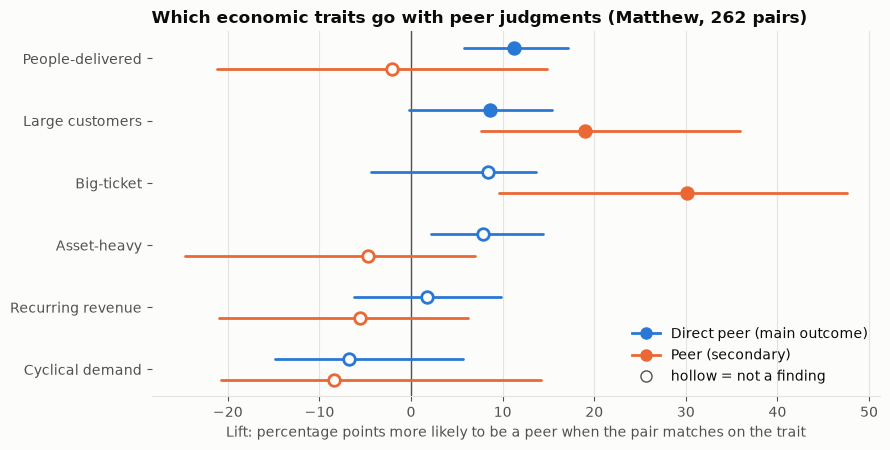

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.6))
ylab = [t for t in TRAITS]
ypos = {t: i for i, t in enumerate(sorted(TRAITS, key=lambda t: ts.query("trait == @t and cell == 'all' and outcome == 'direct'").lift.iloc[0]))}
for k, o in enumerate(("direct", "peer")):
    d = ts[ts.cell.eq("all") & ts.outcome.eq(o)]
    for _, r in d.iterrows():
        y = ypos[r.trait] + (0.17 if o == "direct" else -0.17)
        ax.plot([r.ci_low * 100, r.ci_high * 100], [y, y], color=COLOR[o], lw=2, solid_capstyle="round", zorder=2)
        ax.scatter(r.lift * 100, y, s=70, zorder=3, color=COLOR[o] if r.finding else SURFACE,
                   edgecolors=COLOR[o], linewidths=2)
ax.axvline(0, color=INK2, lw=1, zorder=1)
ax.set_yticks(list(ypos.values()), [TLABEL[t] for t in ypos])
ax.set_xlabel("Lift: percentage points more likely to be a peer when the pair matches on the trait")
ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
from matplotlib.lines import Line2D
handles = [Line2D([], [], marker="o", ls="-", color=COLOR[o], markerfacecolor=COLOR[o], markersize=8, lw=2, label=OUTLABEL[o]) for o in ("direct", "peer")]
handles.append(Line2D([], [], marker="o", ls="", color=INK2, markerfacecolor=SURFACE, markersize=8, label="hollow = not a finding"))
ax.legend(handles=handles, loc="lower right", frameon=False)
ax.set_title("Which economic traits go with peer judgments (Matthew, 262 pairs)", loc="left")
fig.tight_layout(); fig.savefig(TFIG / "trait_lift_intervals.png", dpi=200); plt.show()

#### Across the slices (Aziz's sub-segment question)

Lift by kind of target, in percentage points. Blue = matching on the trait goes with *more* peers, red = *fewer*,
gray = about zero. **Bold with a star = finding.** A dagger (†) marks a thin slice (fewer than 20 pairs or 50 of the
200 bootstrap draws usable): don't read it. Big-ticket and people-delivered are rare traits (few pairs differ on
them; 55-76 usable draws), so even their unmarked cells are less certain than the others. Each slice is tested against zero, not against the other slices, so
"larger in this slice than that one" is a pattern to check on v3 labels, not a result.

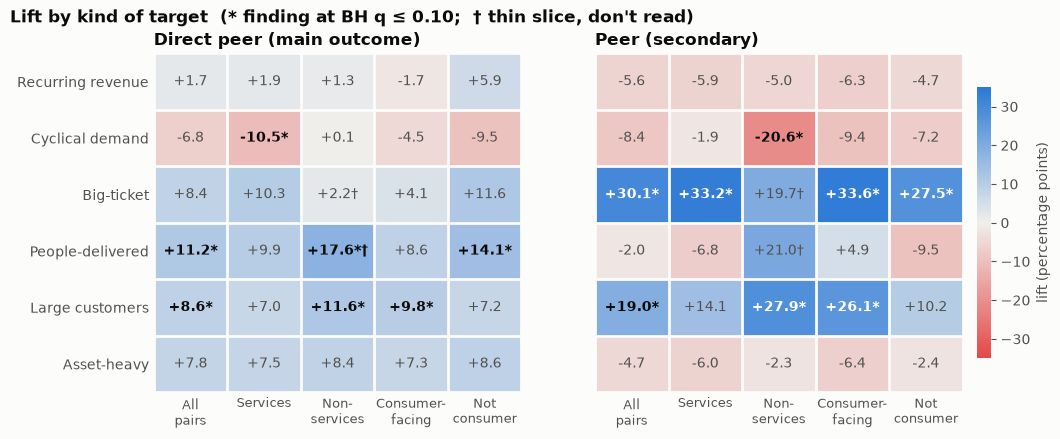

In [7]:
cmap = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])
HLABEL = {"all": "All\npairs", "services_yes": "Services", "services_no": "Non-\nservices",
          "consumers_yes": "Consumer-\nfacing", "consumers_no": "Not\nconsumer"}
vmax = float(np.ceil(ts.lift.abs().max() * 100 / 5) * 5)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), sharey=True)
for ax, o in zip(axes, ("direct", "peer")):
    d = ts[ts.outcome.eq(o)].set_index(["trait", "cell"])
    grid = np.array([[d.loc[(t, c), "lift"] * 100 for c in CELLS] for t in TRAITS])
    ax.imshow(grid, cmap=cmap, vmin=-vmax, vmax=vmax, aspect="auto")
    for i, t in enumerate(TRAITS):
        for j, c in enumerate(CELLS):
            r = d.loc[(t, c)]
            thin = r.pairs < 20 or r.boot_usable < 50
            txt = f"{r.lift * 100:+.1f}" + ("*" if r.finding else "") + ("†" if thin else "")
            strong = abs(r.lift * 100) > 0.62 * vmax
            ax.text(j, i, txt, ha="center", va="center", fontsize=10, fontweight="bold" if r.finding else "normal",
                    color="#ffffff" if strong else (INK if r.finding else INK2))
    ax.set_xticks(range(len(CELLS)), [HLABEL[c] for c in CELLS], fontsize=9)
    ax.set_yticks(range(len(TRAITS)), [TLABEL[t] for t in TRAITS])
    ax.set_title(OUTLABEL[o], loc="left")
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_xticks(np.arange(-0.5, len(CELLS)), minor=True); ax.set_yticks(np.arange(-0.5, len(TRAITS)), minor=True)
    ax.grid(which="minor", color=SURFACE, lw=2); ax.tick_params(which="minor", length=0)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(-vmax, vmax))
cb = fig.colorbar(sm, ax=axes, shrink=0.8, pad=0.015); cb.set_label("lift (percentage points)"); cb.outline.set_visible(False)
fig.suptitle("Lift by kind of target  (* finding at BH q ≤ 0.10;  † thin slice, don't read)", x=0.01, ha="left", fontweight="bold")
fig.savefig(TFIG / "trait_lift_by_slice.png", dpi=200, bbox_inches="tight"); plt.show()

#### How the shuffle test decides (example: large customers)

To see how big a lift chance alone produces, each trait's answers were shuffled across the 533 companies 1,000 times
and the whole estimator rerun. The gray bars are those 1,000 shuffled lifts; the colored line is the real one. The
p-value is the share of shuffles at least as far from zero as the real lift.

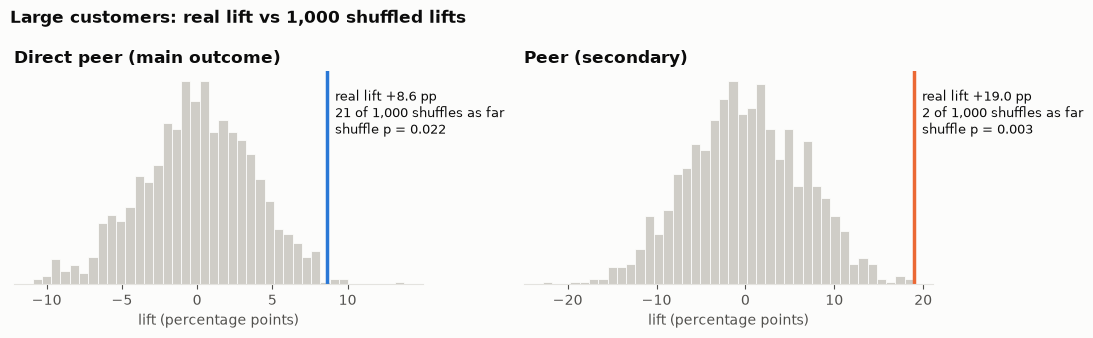

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, o in zip(axes, ("direct", "peer")):
    null = tperm.query("trait == 'large_customers' and outcome == @o and cell == 'all' and supported").lift * 100
    real = ts.query("trait == 'large_customers' and outcome == @o and cell == 'all'").iloc[0]
    ax.hist(null, bins=40, color="#cfcdc7", edgecolor=SURFACE, linewidth=0.6)
    ax.axvline(real.lift * 100, color=COLOR[o], lw=2.5)
    as_far = int((null.abs() >= abs(real.lift * 100)).sum())
    ax.text(real.lift * 100, ax.get_ylim()[1] * 0.92, f"  real lift {real.lift * 100:+.1f} pp\n  {as_far} of {len(null):,} shuffles as far\n  shuffle p = {real.perm_p:.3f}",
            color=INK, va="top", fontsize=9)
    ax.set_title(OUTLABEL[o], loc="left"); ax.set_xlabel("lift (percentage points)")
    ax.set_yticks([])
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
fig.suptitle("Large customers: real lift vs 1,000 shuffled lifts", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(TFIG / "shuffle_test_large_customers.png", dpi=200); plt.show()

#### How Benjamini-Hochberg decides

Each dot is one of the 60 tests, sorted by its shuffle p-value (log scale). Read on its own, any test under the
dashed line (p = 0.05) would look significant. Benjamini-Hochberg instead compares the k-th smallest p-value with
the rising bar k/60 × 10% (solid line), finds the last test under its bar, and accepts that one and every smaller
p-value. That keeps the expected share of false findings among the accepted ones at or below 10%.

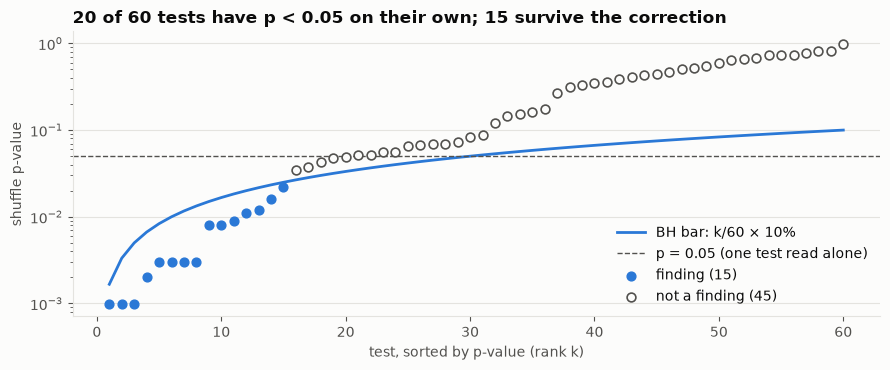

In [9]:
p = ts.perm_p.fillna(1.0).sort_values().reset_index(drop=True)
fin = ts.loc[ts.perm_p.fillna(1.0).sort_values().index, "finding"].reset_index(drop=True)
k = np.arange(1, len(p) + 1)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(k, k / len(p) * 0.10, color=COLOR["direct"], lw=2, label="BH bar: k/60 × 10%")
ax.axhline(0.05, color=INK2, lw=1, ls="--", label="p = 0.05 (one test read alone)")
ax.scatter(k[fin], p[fin], s=40, color=COLOR["direct"], zorder=3, label=f"finding ({int(fin.sum())})")
ax.scatter(k[~fin], p[~fin], s=40, color=SURFACE, edgecolors=INK2, linewidths=1.2, zorder=3, label=f"not a finding ({int((~fin).sum())})")
ax.set_yscale("log"); ax.set_xlabel("test, sorted by p-value (rank k)"); ax.set_ylabel("shuffle p-value")
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.legend(frameon=False, loc="lower right")
alone = int((p < 0.05).sum())
ax.set_title(f"{alone} of 60 tests have p < 0.05 on their own; {int(fin.sum())} survive the correction", loc="left")
fig.tight_layout(); fig.savefig(TFIG / "benjamini_hochberg.png", dpi=200); plt.show()

#### Can each finding be trusted? (reliability)

For every finding: how many pairs and targets it rests on, how many of the 200 bootstrap draws were usable, whether
the 95% interval excludes zero, and whether the doubly robust check (a second estimator) points the same way.

In [10]:
SLABEL = {"all": "all pairs", "services_yes": "services targets", "services_no": "non-services targets",
          "consumers_yes": "consumer-facing targets", "consumers_no": "not consumer-facing targets"}
f = ts[ts.finding].copy()
rel = pd.DataFrame({
    "trait": f.trait.map(TLABEL), "outcome": f.outcome, "slice": f.cell.map(SLABEL),
    "lift (pp)": (f.lift * 100).round(1), "pairs": f.pairs, "targets": f.targets, "usable draws": f.boot_usable,
    "interval excludes 0": ((f.ci_low > 0) | (f.ci_high < 0)).map({True: "yes", False: "no"}),
    "doubly robust same sign": (np.sign(f.lift) == np.sign(f.dr_adjusted_difference)).map({True: "yes", False: "no"}),
})
rel["trust"] = np.where((rel["interval excludes 0"] == "yes") & (rel["doubly robust same sign"] == "yes") & (rel["usable draws"] >= 150) & (rel.pairs >= 20), "solid",
               np.where((rel.pairs < 20) | (rel["usable draws"] < 50), "too thin to read",
               np.where(rel["interval excludes 0"] == "yes", "promising, check on v3", "weak")))
rel["trust"] = pd.Categorical(rel["trust"], ["solid", "promising, check on v3", "weak", "too thin to read"], ordered=True)
display(rel.sort_values(["trust", "outcome", "trait"]).reset_index(drop=True))

,trait,outcome,slice,lift (pp),pairs,targets,usable draws,interval excludes 0,doubly robust same sign,trust
0,Large customers,direct,non-services targets,11.6,90,14,199,yes,yes,solid
1,Large customers,direct,consumer-facing targets,9.8,124,22,200,yes,yes,solid
2,Large customers,peer,all pairs,19.0,232,40,200,yes,yes,solid
3,Large customers,peer,non-services targets,27.9,90,14,199,yes,yes,solid
4,Large customers,peer,consumer-facing targets,26.1,124,22,200,yes,yes,solid
5,People-delivered,direct,all pairs,11.2,85,29,55,yes,yes,"promising, check on v3"
6,People-delivered,direct,not consumer-facing targets,14.1,42,14,54,yes,yes,"promising, check on v3"
7,Big-ticket,peer,all pairs,30.1,70,26,76,yes,yes,"promising, check on v3"
8,Big-ticket,peer,services targets,33.2,53,20,76,yes,yes,"promising, check on v3"
9,Big-ticket,peer,consumer-facing targets,33.6,21,11,76,yes,no,"promising, check on v3"


#### What this means and what's next

- **Large customers is the one solid result.** Pairs whose companies both sell mainly to large enterprises or
  government (or both don't) are judged peers more often, on both outcomes, with full support. B3 has no direct
  customer-size signal. Caveat: it sits close to rubric v2's loose "same customers" question, so part of it may be
  that question restated; the rubric v3 rerun is the test.
- **People-delivered (direct) and big-ticket (peer only)** pass the correction but are rare traits with shaky
  intervals: promising, not settled.
- **Cyclical demand** shows two negative findings whose intervals cross zero: an open question, not a result.
- **Recurring revenue and asset-heavy:** no finding.
- **Next:** rerun this plan unchanged on rubric v3 consensus labels. If large customers holds, it is the first trait
  to try in the selector prompt, scored in the improvement ledger.

In [11]:
# checks for the trait run (shown with the other checks in section 4)
checks.add("trait run: 60 tests, all supported", len(ts) == 60 and ts.status.eq("supported").all())
def bh(pvals):
    m = len(pvals); order = np.argsort(pvals); ranked = pvals[order] * m / np.arange(1, m + 1)
    q = np.minimum.accumulate(ranked[::-1])[::-1].clip(max=1.0); out = np.empty(m); out[order] = q; return out
checks.add("trait run: BH q recomputes from the shuffle p-values",
           np.allclose(bh(ts.perm_p.fillna(1.0).to_numpy()), ts.bh_q.to_numpy(), atol=1e-9))
checks.add("trait run: finding = (q <= 0.10)", ts.finding.equals(ts.bh_q.le(0.10)))
committed = subprocess.run(["git", "show", f"{tm['commit']}:v2/09_analysis/PREREG_TRAITS.md"], cwd=ROOT,
                           capture_output=True).stdout
import hashlib
prereg_sha = tm["sources"]["v2/09_analysis/PREREG_TRAITS.md"]
# The run recorded the hash of the plan file as checked out (CRLF on Windows, core.autocrlf); git stores it with LF.
# The plan at run time must equal the committed plan. Dated amendments added to the file after the run are listed
# in it, so the plan file is left out of the "inputs unchanged" check.
def plan_matches(committed_bytes, recorded_sha):
    return recorded_sha in (hashlib.sha256(committed_bytes).hexdigest(),
                            hashlib.sha256(committed_bytes.replace(b"\r\n", b"\n").replace(b"\n", b"\r\n")).hexdigest())
checks.add("trait run: the plan it ran under is the committed one", plan_matches(committed, prereg_sha),
           f"commit {tm['commit'][:8]}")
changed = [p for p, h in tm["sources"].items() if not p.endswith("PREREG_TRAITS.md") and nb.sha256(ROOT / p) != h]
checks.add("trait run: inputs unchanged since the run (plan amendments are dated in the plan)", not changed,
           ", ".join(changed))
checks.add("trait run: traits at prompt 2026-11-24a", tm["trait_prompt_versions"] == ["2026-11-24a"])

### 3.2 Round 2: four more traits (its own pre-registered family)
<!-- v2 trait round 2 -->

**Why a round 2.** In round 1, cyclical demand split true direct peers as often as non-peers, and the model's
reasons showed the two facts that actually decided its answer: new builds vs maintenance of an installed base, and
who ultimately pays. Round 2 asks those directly (**maintenance-led**, **publicly funded**) and adds two
private-equity value drivers (**serial acquirer**, **mission-critical**).

**How to read it.** The same estimator, outcomes, slices, shuffle test and bootstrap as round 1, with one change:
the covariates now include **all six round-1 traits** as well as B3's 12 signals, so a round-2 lift is what the
trait adds beyond everything measured so far. Round 2 was designed after seeing round 1, so it is **its own test
family** (4 traits x 5 slices x 2 outcomes = 40 tests, Benjamini-Hochberg across those 40 only) and its findings are
**exploratory leads** until the same plan holds on the rubric v3 labels. Round 1's results stay exactly as run. The
plan: [`PREREG_TRAITS_R2.md`](PREREG_TRAITS_R2.md), committed before the run.

In [12]:
TRAIT_RUN2 = paths.path(cur["analysis"]["trait_uplift_r2"]["run"])
tm2 = json.loads((TRAIT_RUN2 / "manifest.json").read_text())
ts2 = pd.read_csv(TRAIT_RUN2 / "summary.csv")
tperm2 = pd.read_csv(TRAIT_RUN2 / "permutations.csv")
TRAITS2 = tm2["tested_traits"]
TLABEL.update({"maintenance_led": "Maintenance-led", "publicly_funded": "Publicly funded",
               "serial_acquirer": "Serial acquirer", "mission_critical": "Mission-critical"})
TFIG2 = paths.out("09_analysis") / "trait_uplift" / TRAIT_RUN2.name / "figures" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
TFIG2.mkdir(parents=True, exist_ok=False)
display(pd.Series({"run": TRAIT_RUN2.name, "cohort": f"{tm2['cohort']} ({tm2['pairs']} pairs, {tm2['targets']} targets)",
                   "plan committed": tm2["commit"][:8], "tested traits": ", ".join(TLABEL[t] for t in TRAITS2),
                   "covariates": tm2["settings"]["covariates"], "tests (BH family)": tm2["settings"]["bh_family"],
                   "trait prompts": ", ".join(tm2["trait_prompt_versions"])}, name="round-2 run").to_frame())
nb.inputs([str((TRAIT_RUN2 / "summary.csv").relative_to(ROOT)).replace("\\", "/"), cur["traits_r2"]["table"],
           cur["analysis"]["trait_uplift_r2"]["prereg"]])

,round-2 run
run,20261124T111715563218Z_r2
cohort,"matthew_v2_262 (262 pairs, 40 targets)"
plan committed,b3b5e309
tested traits,"Maintenance-led, Publicly funded, Serial acquirer, Mission-critical"
covariates,12 B3 signals (current variant) + other traits' match indicators (incl. all six round-...
tests (BH family),40
trait prompts,"2026-11-24a, 2026-11-24b"


,input,rows,sha256,status
0,outputs-local/v2/09_analysis/trait_uplift/20261124T111715563218Z_r2/summary.csv,40.0,5ce39abcabae,new in v1a
1,outputs-local/v2/02_profiles/traits_r2/tables/traits.csv,533.0,23144e34f669,new in v1a
2,v2/09_analysis/PREREG_TRAITS_R2.md,NaN,5465eef1a363,new in v1a


#### Are the new answers stable, and do they track the business?

Left: the 30-company double fill (the keep rule drops a question that flips on more than 20% of companies or is
unknown for more than 20%). Right, for every trait of both rounds: the share of Matthew's **direct-peer** pairs whose
two companies disagree on the trait, next to the share of **non-peer** pairs that disagree. A trait that tracks the
business splits real peers much less often than non-peers; cyclical demand (round 1) did not, which is why round 2
replaced it.

In [13]:
stab = pd.concat([pd.read_csv(paths.path(r) / "../stability/stability.csv").assign(round=k)
                  for k, r in ((1, cur["traits"]["test_runs"][0]), (2, cur["traits_r2"]["test_runs"][0]))])
stab = stab[stab.kind.eq("trait")]
display(pd.DataFrame({"round": stab["round"], "trait": stab.question.map(TLABEL), "flip %": (stab.flip_rate * 100).round(1),
                      "unknown %": (stab.unknown_rate_max * 100).round(1), "yes % (run 1)": (stab.yes_rate_run1 * 100).round(0),
                      "verdict": stab.verdict}).reset_index(drop=True))
pairs2 = pd.read_csv(TRAIT_RUN2 / "pair_features.csv", dtype={"target": str, "comp": str})
t1 = pd.read_csv(paths.path(cur["traits"]["table"]), dtype=str).set_index("IQ_COMPANY_ID")
t2 = pd.read_csv(paths.path(cur["traits_r2"]["table"]), dtype=str).set_index("IQ_COMPANY_ID")
rows = []
for rnd, table, names in ((1, t1, TRAITS), (2, t2, TRAITS2)):
    for c in names:
        a, b = pairs2.target.map(table[c]), pairs2.comp.map(table[c])
        ok = a.isin(["yes", "no"]) & b.isin(["yes", "no"])
        dis = (a != b)[ok]; d = pairs2[ok]
        direct, peer = d.grade.astype(float).eq(2), d.grade.astype(float).ge(1)
        rows.append({"round": rnd, "trait": TLABEL[c], "yes % (533 companies)": round((table[c] == "yes").mean() * 100, 1),
                     "direct-peer pairs that disagree %": round(dis[direct].mean() * 100, 1),
                     "non-peer pairs that disagree %": round(dis[~peer].mean() * 100, 1)})
diag = pd.DataFrame(rows)
diag["tracks the business"] = np.where(diag["direct-peer pairs that disagree %"] < 0.6 * diag["non-peer pairs that disagree %"], "yes",
                              np.where(diag["direct-peer pairs that disagree %"] < diag["non-peer pairs that disagree %"], "weakly", "no"))
display(diag)

,round,trait,flip %,unknown %,yes % (run 1),verdict
0,1,Recurring revenue,0.0,0.0,80.0,keep
1,1,Cyclical demand,3.3,0.0,40.0,keep
2,1,Big-ticket,3.3,0.0,10.0,keep
3,1,People-delivered,0.0,0.0,13.0,keep
4,1,Large customers,3.4,3.3,57.0,keep
5,1,Asset-heavy,6.7,0.0,37.0,keep
6,2,Maintenance-led,3.4,3.3,3.0,keep
7,2,Publicly funded,0.0,3.3,13.0,keep
8,2,Serial acquirer,0.0,0.0,10.0,keep
9,2,Mission-critical,6.7,0.0,47.0,keep


,round,trait,yes % (533 companies),direct-peer pairs that disagree %,non-peer pairs that disagree %,tracks the business
0,1,Recurring revenue,74.7,21.7,29.5,weakly
1,1,Cyclical demand,44.5,21.7,20.5,no
2,1,Big-ticket,11.8,5.0,15.4,yes
3,1,People-delivered,12.8,3.3,7.7,yes
4,1,Large customers,42.2,18.3,50.0,yes
5,1,Asset-heavy,39.4,6.7,17.9,yes
6,2,Maintenance-led,4.1,5.1,14.3,yes
7,2,Publicly funded,5.4,6.8,5.1,no
8,2,Serial acquirer,6.0,11.7,14.1,weakly
9,2,Mission-critical,42.2,8.3,37.2,yes


#### The headline: one row per round-2 trait

Same layout as round 1: lift on all pairs with its 95% interval, the BH-corrected p-value within round 2's family of
40 (`q`; a finding when q <= 0.10), how many of the 5 slices are findings, and a plain reading.

In [14]:
def summarize_trait(tsx, trait):
    rows = tsx[tsx.trait.eq(trait)]
    a = rows[rows.cell.eq("all")].set_index("outcome")
    fd, fp = rows[rows.outcome.eq("direct")].finding.sum(), rows[rows.outcome.eq("peer")].finding.sum()
    support = int(a.boot_usable.min())
    found = rows[rows.finding]
    if fd and fp and support >= 150:
        read = "Strongest: findings on both outcomes, full support"
    elif len(found) and (found.lift < 0).all():
        read = "Negative and unexplained: check the intervals"
    elif fd and not fp:
        read = "Direct peer only" + ("; rare trait, shaky interval" if support < 150 else "")
    elif fp and not fd:
        read = "Peer outcome only (loose v2 wording)" + ("; rare trait" if support < 150 else "")
    else:
        read = "No signal" + (" (rare trait, thin support)" if support < 150 else "")
    out = {"trait": TLABEL[trait]}
    for o in ("direct", "peer"):
        r = a.loc[o]
        out[f"{o}: lift (pp)"] = "unsupported" if pd.isna(r.lift) else f"{pp(r.lift)}  [{pp(r.ci_low)}, {pp(r.ci_high)}]"
        out[f"{o}: q"] = round(r.bh_q, 3)
        out[f"{o}: finding slices"] = f"{int(fd if o == 'direct' else fp)} of 5"
    out["usable bootstrap draws"] = support
    out["reading"] = read
    return out

head2 = pd.DataFrame([summarize_trait(ts2, t) for t in TRAITS2]).set_index("trait")
display(head2.style.apply(shade, subset=["direct: q", "peer: q"]).format({"direct: q": "{:.3f}", "peer: q": "{:.3f}"}))

,direct: lift (pp),direct: q,direct: finding slices,peer: lift (pp),peer: q,peer: finding slices,usable bootstrap draws,reading
trait,,,,,,,,
Maintenance-led,unsupported,1.000,0 of 5,unsupported,1.000,0 of 5,0,"No signal (rare trait, thin support)"
Publicly funded,unsupported,1.000,0 of 5,unsupported,1.000,0 of 5,7,"No signal (rare trait, thin support)"
Serial acquirer,unsupported,1.000,0 of 5,unsupported,1.000,0 of 5,120,"No signal (rare trait, thin support)"
Mission-critical,"+10.6 [+4.3, +18.3]",0.040,5 of 5,"+25.1 [+9.4, +42.4]",0.013,5 of 5,200,"Strongest: findings on both outcomes, full support"


#### Lift with 95% intervals, all pairs (round 2)

Filled dots are findings within round 2's family; hollow dots are not.

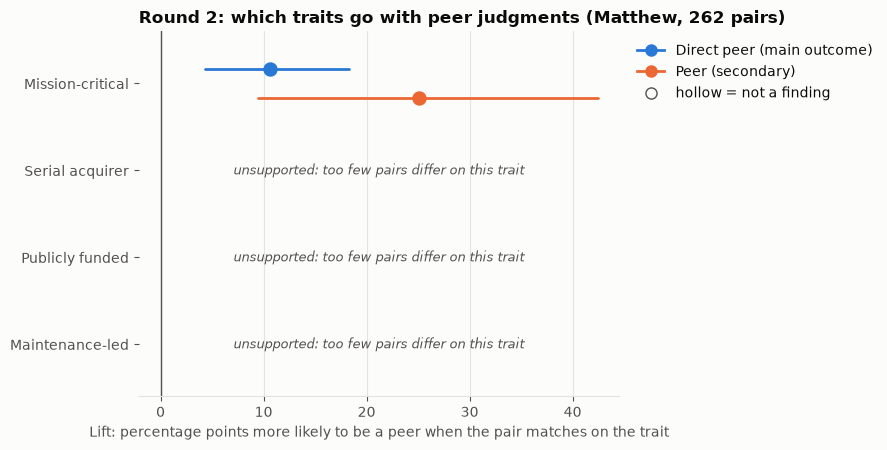

In [15]:
def interval_chart(tsx, traits, title, path):
    fig, ax = plt.subplots(figsize=(9, 0.75 * len(traits) + 1.6))
    order = sorted(traits, key=lambda t: np.nan_to_num(tsx.query("trait == @t and cell == 'all' and outcome == 'direct'").lift.iloc[0], nan=-1))
    ypos = {t: i for i, t in enumerate(order)}
    for o in ("direct", "peer"):
        for _, r in tsx[tsx.cell.eq("all") & tsx.outcome.eq(o)].iterrows():
            if pd.isna(r.lift):
                continue
            y = ypos[r.trait] + (0.17 if o == "direct" else -0.17)
            ax.plot([r.ci_low * 100, r.ci_high * 100], [y, y], color=COLOR[o], lw=2, solid_capstyle="round", zorder=2)
            ax.scatter(r.lift * 100, y, s=70, zorder=3, color=COLOR[o] if r.finding else SURFACE, edgecolors=COLOR[o], linewidths=2)
    ax.axvline(0, color=INK2, lw=1, zorder=1)
    ax.set_yticks(list(ypos.values()), [TLABEL[t] for t in ypos])
    ax.set_ylim(-0.6, len(order) - 0.4)
    for t in order:
        if tsx.query("trait == @t and cell == 'all'").lift.isna().all():
            ax.text(0.5, ypos[t], "unsupported: too few pairs differ on this trait", transform=ax.get_yaxis_transform(),
                    ha="center", va="center", fontsize=9, color=INK2, style="italic")
    ax.set_xlabel("Lift: percentage points more likely to be a peer when the pair matches on the trait")
    ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    from matplotlib.lines import Line2D
    handles = [Line2D([], [], marker="o", ls="-", color=COLOR[o], markerfacecolor=COLOR[o], markersize=8, lw=2, label=OUTLABEL[o]) for o in ("direct", "peer")]
    handles.append(Line2D([], [], marker="o", ls="", color=INK2, markerfacecolor=SURFACE, markersize=8, label="hollow = not a finding"))
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
    ax.set_title(title, loc="left")
    fig.tight_layout(); fig.savefig(path, dpi=200, bbox_inches="tight"); plt.show()

interval_chart(ts2, TRAITS2, "Round 2: which traits go with peer judgments (Matthew, 262 pairs)", TFIG2 / "trait_lift_intervals_r2.png")

#### Across the slices (round 2)

Same encoding as round 1: blue = more peers when the pair matches, red = fewer; **bold with a star = finding** within
round 2's family; a dagger (†) marks a thin slice (fewer than 20 pairs or fewer than 50 of the 200 bootstrap draws
usable), not to be read. "n/a" marks an unsupported cell: too few pairs differ on the trait for every fold to
be fitted, so there is no estimate (not a zero).

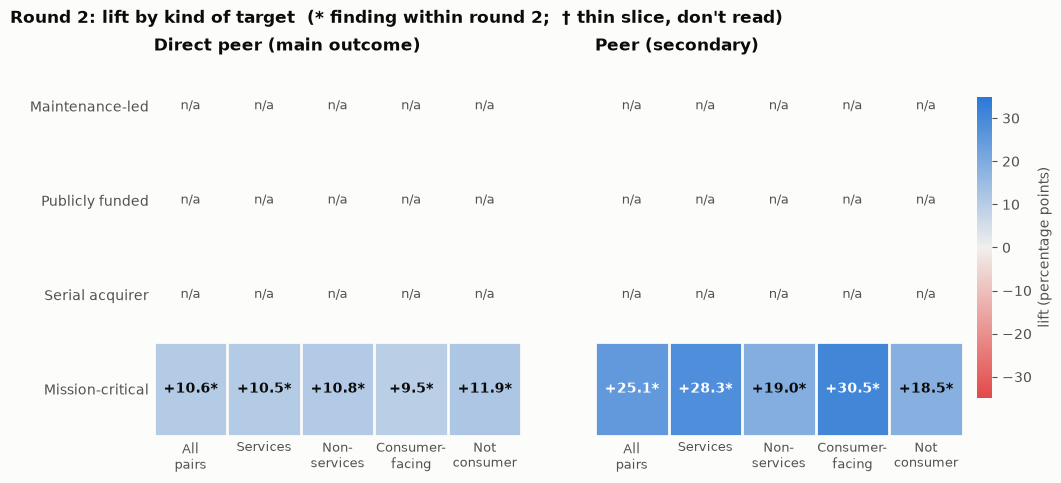

In [16]:
def slice_heatmap(tsx, traits, title, path):
    vmax = float(np.ceil(np.nanmax(tsx.lift.abs()) * 100 / 5) * 5)
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 0.75 * len(traits) + 1.9), sharey=True)
    for ax, o in zip(axes, ("direct", "peer")):
        d = tsx[tsx.outcome.eq(o)].set_index(["trait", "cell"])
        grid = np.array([[d.loc[(t, c), "lift"] * 100 for c in CELLS] for t in traits])
        ax.imshow(np.ma.masked_invalid(grid), cmap=cmap, vmin=-vmax, vmax=vmax, aspect="auto")
        for i, t in enumerate(traits):
            for j, c in enumerate(CELLS):
                r = d.loc[(t, c)]
                if pd.isna(r.lift):
                    ax.text(j, i, "n/a", ha="center", va="center", fontsize=9, color=INK2)
                    continue
                thin = r.pairs < 20 or r.boot_usable < 50
                txt = f"{r.lift * 100:+.1f}" + ("*" if r.finding else "") + ("†" if thin else "")
                strong = abs(r.lift * 100) > 0.62 * vmax
                ax.text(j, i, txt, ha="center", va="center", fontsize=10, fontweight="bold" if r.finding else "normal",
                        color="#ffffff" if strong else (INK if r.finding else INK2))
        ax.set_xticks(range(len(CELLS)), [HLABEL[c] for c in CELLS], fontsize=9)
        ax.set_yticks(range(len(traits)), [TLABEL[t] for t in traits])
        ax.set_title(OUTLABEL[o], loc="left"); ax.tick_params(length=0)
        for s in ax.spines.values():
            s.set_visible(False)
        ax.set_xticks(np.arange(-0.5, len(CELLS)), minor=True); ax.set_yticks(np.arange(-0.5, len(traits)), minor=True)
        ax.grid(which="minor", color=SURFACE, lw=2); ax.tick_params(which="minor", length=0)
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(-vmax, vmax))
    cb = fig.colorbar(sm, ax=axes, shrink=0.8, pad=0.015); cb.set_label("lift (percentage points)"); cb.outline.set_visible(False)
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    fig.savefig(path, dpi=200, bbox_inches="tight"); plt.show()

slice_heatmap(ts2, TRAITS2, "Round 2: lift by kind of target  (* finding within round 2;  † thin slice, don't read)",
              TFIG2 / "trait_lift_by_slice_r2.png")

#### The shuffle test for round 2's strongest result

The round-2 trait with the smallest shuffle p-value on all pairs (direct peer), against its 1,000 shuffled lifts.

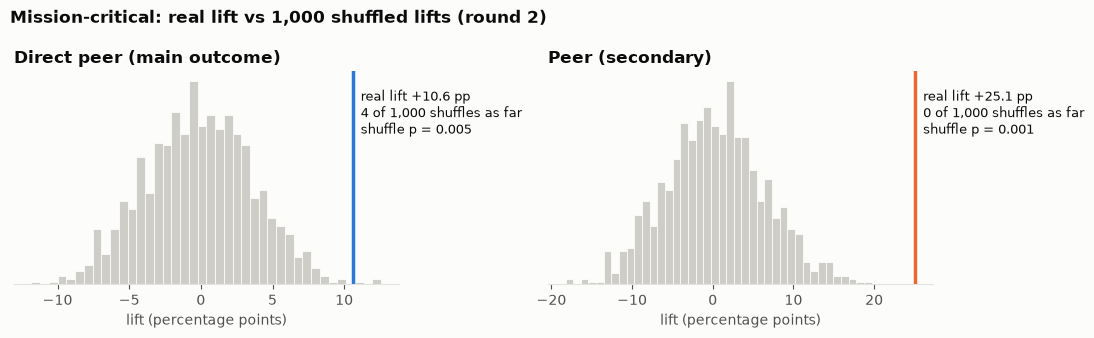

In [17]:
def shuffle_chart(tsx, tpermx, trait, title, path):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
    for ax, o in zip(axes, ("direct", "peer")):
        null = tpermx.query("trait == @trait and outcome == @o and cell == 'all' and supported").lift * 100
        real = tsx.query("trait == @trait and outcome == @o and cell == 'all'").iloc[0]
        ax.hist(null, bins=40, color="#cfcdc7", edgecolor=SURFACE, linewidth=0.6)
        if pd.notna(real.lift):
            ax.axvline(real.lift * 100, color=COLOR[o], lw=2.5)
            as_far = int((null.abs() >= abs(real.lift * 100)).sum())
            ax.text(real.lift * 100, ax.get_ylim()[1] * 0.92,
                    f"  real lift {real.lift * 100:+.1f} pp\n  {as_far} of {len(null):,} shuffles as far\n  shuffle p = {real.perm_p:.3f}",
                    color=INK, va="top", fontsize=9)
        ax.set_title(OUTLABEL[o], loc="left"); ax.set_xlabel("lift (percentage points)"); ax.set_yticks([])
        for s in ("top", "right", "left"):
            ax.spines[s].set_visible(False)
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); fig.savefig(path, dpi=200); plt.show()

top2 = ts2.query("cell == 'all' and outcome == 'direct'").sort_values("perm_p").trait.iloc[0]
shuffle_chart(ts2, tperm2, top2, f"{TLABEL[top2]}: real lift vs 1,000 shuffled lifts (round 2)", TFIG2 / f"shuffle_test_{top2}.png")

#### Benjamini-Hochberg within round 2

The 40 round-2 tests sorted by shuffle p-value against the rising bar k/40 x 10%. Round 1's 60 tests are a separate
family and are not re-corrected here.

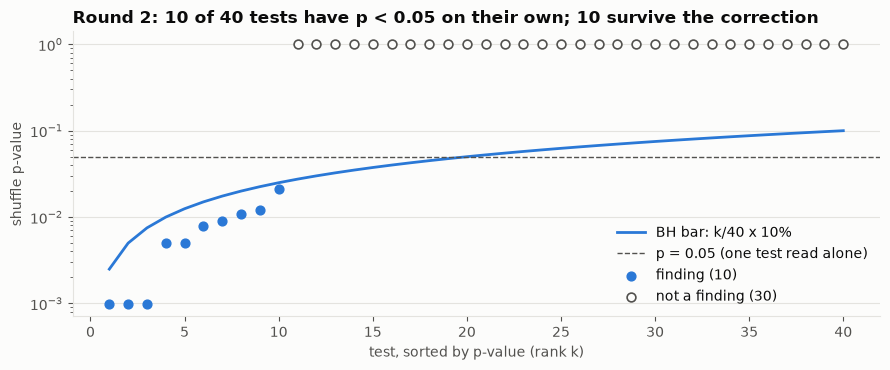

In [18]:
def bh_chart(tsx, title_prefix, path):
    p = tsx.perm_p.fillna(1.0).sort_values().reset_index(drop=True)
    fin = tsx.loc[tsx.perm_p.fillna(1.0).sort_values().index, "finding"].reset_index(drop=True)
    m = len(p); k = np.arange(1, m + 1)
    fig, ax = plt.subplots(figsize=(9, 3.8))
    ax.plot(k, k / m * 0.10, color=COLOR["direct"], lw=2, label=f"BH bar: k/{m} x 10%")
    ax.axhline(0.05, color=INK2, lw=1, ls="--", label="p = 0.05 (one test read alone)")
    ax.scatter(k[fin], p[fin], s=40, color=COLOR["direct"], zorder=3, label=f"finding ({int(fin.sum())})")
    ax.scatter(k[~fin], p[~fin], s=40, color=SURFACE, edgecolors=INK2, linewidths=1.2, zorder=3, label=f"not a finding ({int((~fin).sum())})")
    ax.set_yscale("log"); ax.set_xlabel("test, sorted by p-value (rank k)"); ax.set_ylabel("shuffle p-value")
    ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.legend(frameon=False, loc="lower right")
    ax.set_title(f"{title_prefix}: {int((p < 0.05).sum())} of {m} tests have p < 0.05 on their own; {int(fin.sum())} survive the correction", loc="left")
    fig.tight_layout(); fig.savefig(path, dpi=200); plt.show()

bh_chart(ts2, "Round 2", TFIG2 / "benjamini_hochberg_r2.png")

#### Can each round-2 finding be trusted? (reliability)

Same rules as round 1: solid = interval excludes zero, the doubly robust check agrees in sign, at least 150 usable
bootstrap draws and at least 20 pairs; too thin = fewer than 20 pairs or fewer than 50 usable draws.

In [19]:
def reliability_for(tsx):
    f = tsx[tsx.finding].copy()
    if f.empty:
        return pd.DataFrame({"note": ["no findings in this family"]})
    rel = pd.DataFrame({
        "trait": f.trait.map(TLABEL), "outcome": f.outcome, "slice": f.cell.map(SLABEL),
        "lift (pp)": (f.lift * 100).round(1), "pairs": f.pairs, "targets": f.targets, "usable draws": f.boot_usable,
        "interval excludes 0": ((f.ci_low > 0) | (f.ci_high < 0)).map({True: "yes", False: "no"}),
        "doubly robust same sign": (np.sign(f.lift) == np.sign(f.dr_adjusted_difference)).map({True: "yes", False: "no"})})
    rel["trust"] = np.where((rel["interval excludes 0"] == "yes") & (rel["doubly robust same sign"] == "yes") & (rel["usable draws"] >= 150) & (rel.pairs >= 20), "solid",
                   np.where((rel.pairs < 20) | (rel["usable draws"] < 50), "too thin to read",
                   np.where(rel["interval excludes 0"] == "yes", "promising, check on v3", "weak")))
    rel["trust"] = pd.Categorical(rel["trust"], ["solid", "promising, check on v3", "weak", "too thin to read"], ordered=True)
    return rel.sort_values(["trust", "outcome", "trait"]).reset_index(drop=True)

display(reliability_for(ts2))

,trait,outcome,slice,lift (pp),pairs,targets,usable draws,interval excludes 0,doubly robust same sign,trust
0,Mission-critical,direct,all pairs,10.6,223,40,200,yes,yes,solid
1,Mission-critical,direct,services targets,10.5,141,26,200,yes,yes,solid
2,Mission-critical,direct,non-services targets,10.8,82,14,197,yes,yes,solid
3,Mission-critical,direct,consumer-facing targets,9.5,117,22,200,yes,yes,solid
4,Mission-critical,direct,not consumer-facing targets,11.9,106,18,200,yes,yes,solid
5,Mission-critical,peer,all pairs,25.1,223,40,200,yes,yes,solid
6,Mission-critical,peer,services targets,28.3,141,26,200,yes,yes,solid
7,Mission-critical,peer,consumer-facing targets,30.5,117,22,200,yes,yes,solid
8,Mission-critical,peer,not consumer-facing targets,18.5,106,18,200,yes,yes,solid
9,Mission-critical,peer,non-services targets,19.0,82,14,197,no,yes,weak


#### Cyclical demand (round 1) next to what replaced it (round 2)

All pairs, both outcomes. Each row keeps its own round and its own correction (`q` is within that round's family);
the rounds are shown side by side, not pooled.

In [20]:
def row_for(tsx, rnd, family, trait):
    out = {"round": rnd, "family (tests)": family, "trait": TLABEL[trait]}
    for o in ("direct", "peer"):
        r = tsx.query("trait == @trait and cell == 'all' and outcome == @o").iloc[0]
        out[f"{o}: lift (pp)"] = "unsupported" if pd.isna(r.lift) else f"{pp(r.lift)}  [{pp(r.ci_low)}, {pp(r.ci_high)}]"
        out[f"{o}: q"] = round(r.bh_q, 3)
        out[f"{o}: finding"] = "yes" if r.finding else "no"
    return out

display(pd.DataFrame([row_for(ts, 1, len(ts), "cyclical_demand"),
                      row_for(ts2, 2, len(ts2), "maintenance_led"),
                      row_for(ts2, 2, len(ts2), "publicly_funded")]))

,round,family (tests),trait,direct: lift (pp),direct: q,direct: finding,peer: lift (pp),peer: q,peer: finding
0,1,60,Cyclical demand,"-6.8 [-14.9, +5.6]",0.148,no,"-8.4 [-20.7, +14.2]",0.295,no
1,2,40,Maintenance-led,unsupported,1.000,no,unsupported,1.000,no
2,2,40,Publicly funded,unsupported,1.000,no,unsupported,1.000,no


#### What round 2 says

- **Mission-critical is the strongest trait so far, in either round.** Pairs whose companies are both hard to switch
  away from (or both easy) are judged direct peers about 11 points more often, beyond B3 and all six round-1 traits
  (+10.6, interval +4.3 to +18.3, every bootstrap draw usable, the doubly robust check +10.2), and a finding in all
  five slices on both outcomes. It also tracks the business in the diagnostic: true direct peers disagree on it
  8% of the time, non-peers 37%. Because round 2 was designed after round 1, this is a **lead**, to confirm with
  the same plan on the rubric v3 labels; if it holds, it is a strong candidate for the selector prompt.
- **Maintenance-led, publicly funded and serial acquirer could not be estimated.** Only 4-6% of companies answer yes,
  so 21-31 of the 262 pairs differ on each, and one of the five folds had too few mismatched pairs every time. As
  pre-registered, they are reported as unsupported (no estimate, p = 1), not as zero. Maintenance-led does track the
  business in the diagnostic (5% vs 14% disagreement); publicly funded does not (7% vs 5%). More labelled pairs with
  these kinds of companies, or the v3 round, are what would make them measurable.
- **Cyclical demand's replacement:** the two facts it was split into are real but rare in this universe, so the
  question round 2 set out to answer about them stays open; cyclical demand's round-1 result stands as run.

In [21]:
# round-2 checks (shown with the others in section 4)
committed2 = subprocess.run(["git", "show", f"{tm2['commit']}:v2/09_analysis/PREREG_TRAITS_R2.md"], cwd=ROOT,
                            capture_output=True).stdout
checks.add("round 2: the plan it ran under is the committed PREREG_TRAITS_R2.md",
           bool(committed2) and plan_matches(committed2, tm2["sources"]["v2/09_analysis/PREREG_TRAITS_R2.md"]),
           f"commit {tm2['commit'][:8]}")
checks.add("round 2: BH family = kept traits x 5 slices x 2 outcomes",
           len(ts2) == tm2["settings"]["bh_family"] == len(TRAITS2) * 5 * 2, f"{len(ts2)} tests, {len(TRAITS2)} traits")
checks.add("round 2: BH q recomputes from the shuffle p-values", np.allclose(bh(ts2.perm_p.fillna(1.0).to_numpy()), ts2.bh_q.to_numpy(), atol=1e-9))
checks.add("round 2: pinned [traits_r2] table has 533 rows, all ok, prompt 2026-11-24b",
           len(t2) == 533 and t2.llm_status.eq("ok").all() and set(t2.prompt_version) == {"2026-11-24b"})
changed2 = [p for p, h in tm2["sources"].items() if not p.endswith("PREREG_TRAITS_R2.md") and nb.sha256(ROOT / p) != h
            and not p.endswith("PREREG_TRAITS.md")]
checks.add("round 2: inputs unchanged since the run", not changed2, ", ".join(changed2))

### 3.3 Improvement ledger: is the pipeline getting closer to the labels? (the north star)

Every pipeline version gets a row: how much of its comp profile reviewers agree with (**precision**: of the comps it
keeps, the share people call peers) and how much of what people call peers it keeps (**recall**), for any peer and
for direct peer, averaged over targets, with 95% intervals. Only labelled pairs count; an unlabelled pair is never a
non-peer. The ledger is append-only: one row per change, so the website can show improvement version by version.

Today it holds the **baseline**: the current pipeline's five filters on Matthew's rubric v2 labels. From here the
model-improvement group adds a row after each prompt change (`progress.py record`, how-to in
[`PROGRESS.md`](PROGRESS.md)), scored on the checking half of the labelled targets, and the cohort switches to the
rubric v3 consensus labels when they exist.

,date,version,who,labels,targets,kept,any peer: precision,any peer: recall,direct: precision,direct: recall
0,2026-11-24,"B3 list, keep all",Michael (baseline),matthew_v2_262,all,262,"67% [58%, 76%]",100%,"21% [14%, 28%]",100%
1,2026-11-24,B3 top 7,Michael (baseline),matthew_v2_262,all,218,"71% [61%, 79%]","90% [85%, 94%]","26% [17%, 36%]","99% [96%, 100%]"
2,2026-11-24,Selector keeps (04),Michael (baseline),matthew_v2_262,all,61,"92% [81%, 100%]","34% [25%, 44%]","73% [55%, 88%]","85% [73%, 95%]"
3,2026-11-24,Agent grade >= 1 (05),Michael (baseline),matthew_v2_262,all,163,"79% [68%, 88%]","72% [60%, 82%]","33% [23%, 43%]","99% [98%, 100%]"
4,2026-11-24,Agent grade 2 (05),Michael (baseline),matthew_v2_262,all,23,100%,"14% [7%, 22%]",100%,"40% [25%, 55%]"


Change recorded with the baseline rows: *baseline: current v1a pipeline (B3 Sonnet + Fiona sub-sector; selector 2026-11-04a; agent 2026-11-05b)*

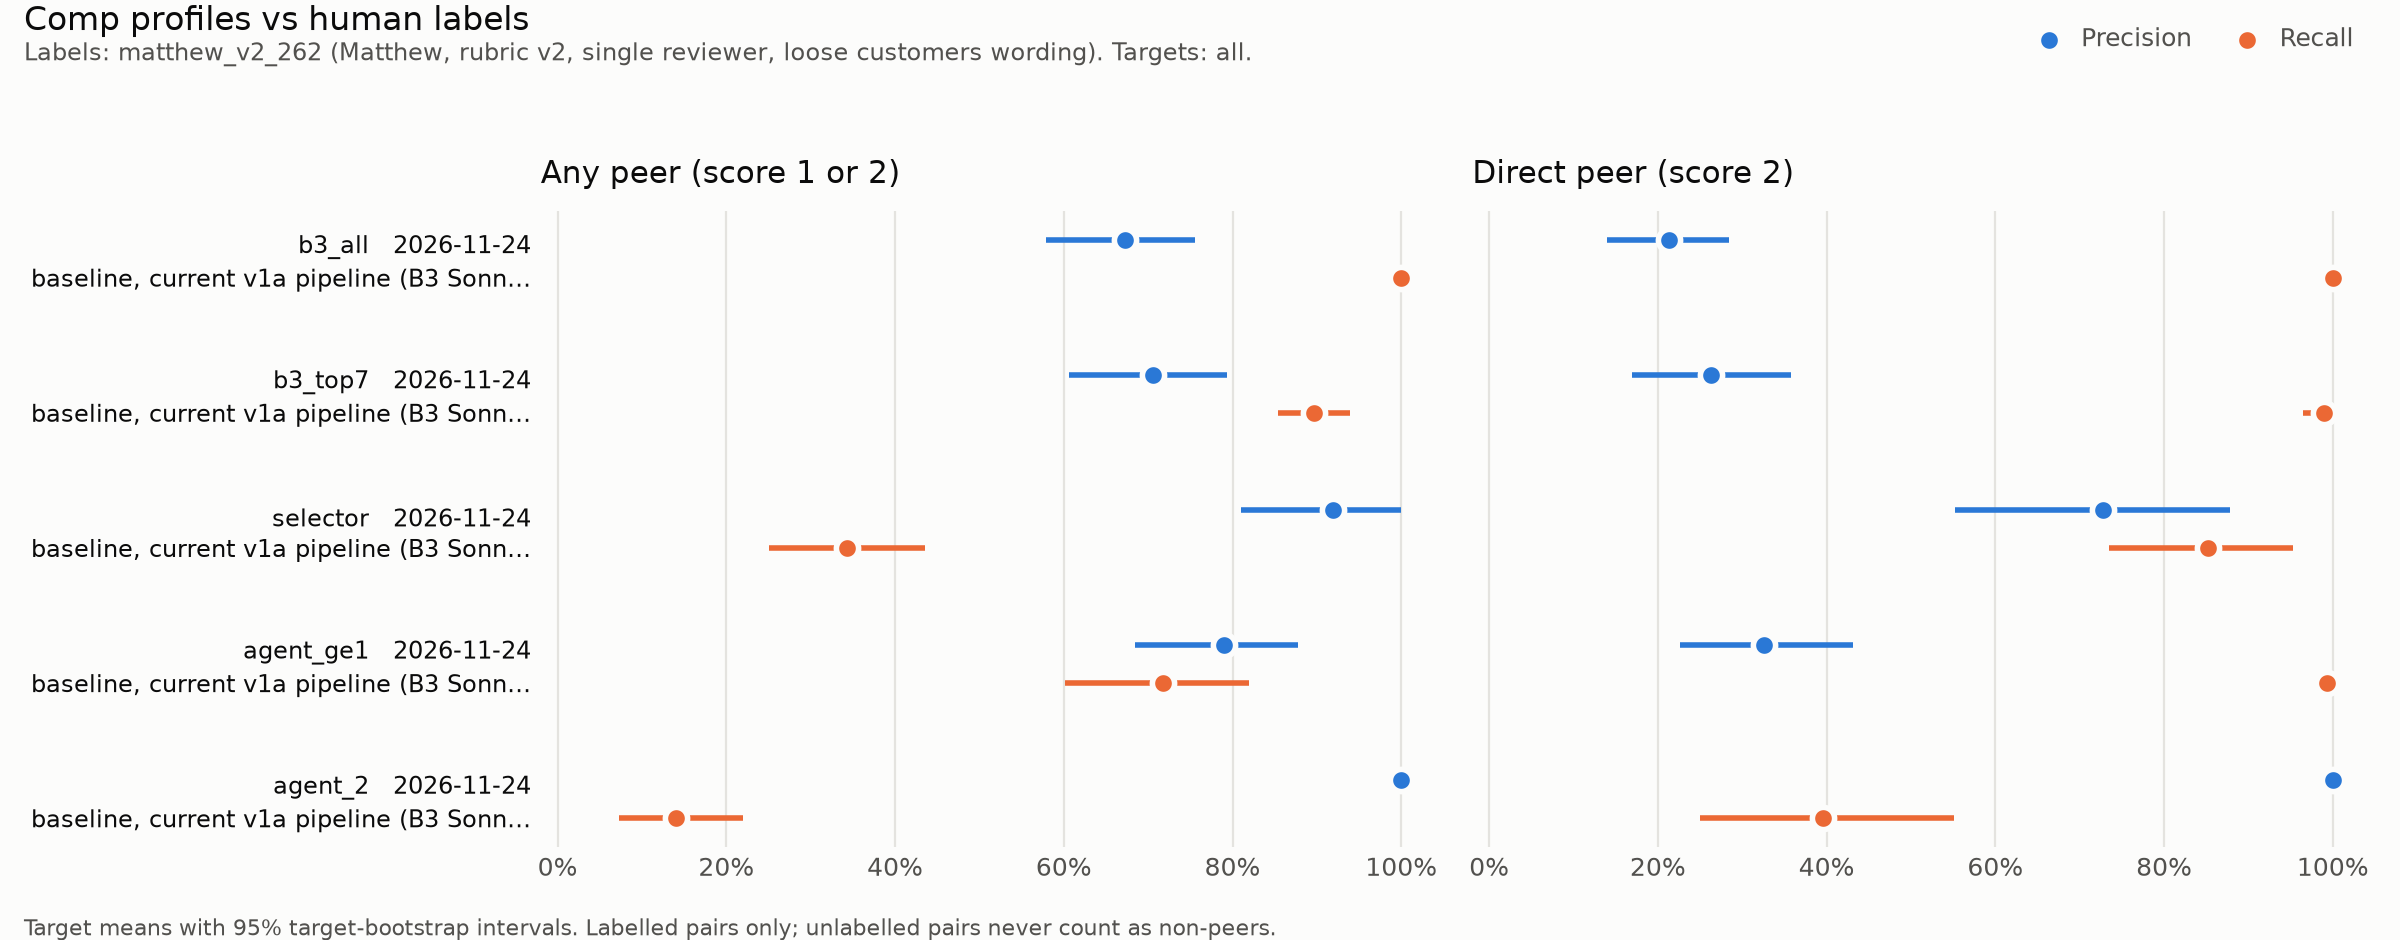

In [22]:
from IPython.display import Image
LEDGER = paths.path(cur["analysis"]["progress"]["ledger"])
led = pd.read_csv(LEDGER)
def ci(m, lo, hi):
    return f"{m:.0%}" if pd.isna(lo) or lo == hi else f"{m:.0%}  [{lo:.0%}, {hi:.0%}]"
NAMES_P = {"b3_all": "B3 list, keep all", "b3_top7": "B3 top 7", "selector": "Selector keeps (04)",
           "agent_ge1": "Agent grade >= 1 (05)", "agent_2": "Agent grade 2 (05)"}
show = pd.DataFrame({
    "date": led.entry_utc.str[:10], "version": led.profile.map(NAMES_P).fillna(led.profile), "who": led.who,
    "labels": led.cohort, "targets": led.split, "kept": led.kept,
    "any peer: precision": [ci(*r) for r in led[["peer_precision_mean", "peer_precision_mean_lo", "peer_precision_mean_hi"]].to_numpy()],
    "any peer: recall": [ci(*r) for r in led[["peer_recall_mean", "peer_recall_mean_lo", "peer_recall_mean_hi"]].to_numpy()],
    "direct: precision": [ci(*r) for r in led[["direct_precision_mean", "direct_precision_mean_lo", "direct_precision_mean_hi"]].to_numpy()],
    "direct: recall": [ci(*r) for r in led[["direct_recall_mean", "direct_recall_mean_lo", "direct_recall_mean_hi"]].to_numpy()],
})
display(show)
display(Markdown(f"Change recorded with the baseline rows: *{led.change.iloc[0]}*"))
display(Image(filename=str(LEDGER.parent / "progress.png")))

**Reading the baseline.** The selector is a precise but narrow filter (it keeps about a third of the peers, and most
of the direct peers); the agent grade keeps most peers at lower precision. A better pipeline version moves a row's
dots right on both precision and recall for the outcome it targets, on targets it was not tuned on.

In [23]:
# ledger checks (shown with the others in section 4)
ag = led[led.profile.eq("agent_ge1")].iloc[0]; se = led[led.profile.eq("selector")].iloc[0]
checks.add("ledger baseline: agent >= 1 matches GRADING_REVIEW (163 kept, 83.4% / 73.9%)",
           ag.kept == 163 and round(ag.peer_precision_pooled, 3) == 0.834 and round(ag.peer_recall_pooled, 3) == 0.739)
checks.add("ledger baseline: selector matches GRADING_REVIEW (61 kept, 95.1% / 31.5%)",
           se.kept == 61 and round(se.peer_precision_pooled, 3) == 0.951 and round(se.peer_recall_pooled, 3) == 0.315)

### 3.4 v1a results (Kethan's facet X-learner and the stage ablation)

### Which facets help identify better comparable companies?
### Two clearly separated X-learner analyses

We investigate the same 293 reviewed company pairs in two ways:

- **[Method A: original 0/1/2 rating](#method-a)** — how does a stronger facet match relate to the expected human rating? Units: **rating points**.
- **[Method B: combined peer/non-peer](#method-b)** — how does a stronger facet match relate to the chance of any acceptable peer label? Units: **percentage points**.
- **[Compare findings and next steps](#comparison)** — which hypotheses persist, and which depend on the outcome definition?

Each method has its own explanation, results, sensitivity analysis and diagnostics. Shared study design appears first. The estimates are exploratory adjusted associations within a selected, single-reviewer cohort, not identified causal effects or improvements in either matching pipeline.

The original `facet_uplift.ipynb` remains the earlier binary technical/raw notebook. The previous stakeholder edition is archived; its binary experiment results are preserved.

In [24]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from matplotlib.colors import ListedColormap
from IPython.display import display, Markdown
# v1a: the pinned runs from current.toml (ROOT and runs come from the setup cell above)
BINARY_RUN = runs["human_peer"]
RATING_RUN = runs["human_rating"]
RUN = BINARY_RUN
manifest = json.loads((RUN / "manifest.json").read_text())
features = pd.read_csv(RUN / "pair_features.csv")
summary = pd.read_csv(RUN / "facet_summary.csv")
effects = pd.read_csv(RUN / "oof_effects.csv")
folds = pd.read_csv(RUN / "fold_diagnostics.csv")
bins = pd.read_csv(RUN / "uplift_bins.csv")
primary = summary[summary.rule.eq("primary")].copy()
assert len(features) == manifest["pairs"] and features.target.nunique() == manifest["targets"]
assert not features.duplicated(["target", "comp"]).any()
# v1a: 12 B3 + 11 agent signals x 2 rules, plus the two stage rows (selector keep, agent grade); v1 had 44
assert len(summary) == 2 * features.filter(regex="^(b3|agent)__").shape[1] + 2
PRESENTATION = paths.out("09_analysis") / "facet_uplift" / RATING_RUN.name / "presentation" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")  # v2: copies go to outputs-local/v2; the pinned run stays in v1a (read only)
PRESENTATION.mkdir(parents=True, exist_ok=False)
NAMES = {"primary_services":"Services", "primary_products":"Products", "customer_segment":"Customers",
         "end_markets":"End markets", "offering_description":"Core offering", "business_model":"Business model",
         "revenue_model":"Revenue model", "value_chain_position":"Value-chain position",
         "geography_served":"Geography", "regulatory_exposure":"Regulation",
         "specialization":"Specialization", "distribution_channels":"Sales channels",
         "sub_sector":"Sub-sector"}  # v1a: Fiona's sub-sector, the 12th B3 signal
BLUE, TEAL, ORANGE, GRAY = "#315b85", "#217f79", "#ba762c", "#a9b1bb"
plt.rcParams.update({"figure.dpi":110, "font.size":11, "axes.spines.top":False,
                     "axes.spines.right":False, "axes.titleweight":"bold"})
def save(fig, name, note):
    fig.text(.02, .012, note, fontsize=9, color="#424b55", va="bottom")
    fig.tight_layout(rect=(0,.065,1,.94))
    fig.savefig(PRESENTATION / (name + ".png"), dpi=170, bbox_inches="tight", facecolor="white")
    plt.show()
def row(source, facet, rule="primary"):
    return summary.loc[summary.source.eq(source)&summary.facet.eq(facet)&summary.rule.eq(rule)].iloc[0]
def pp(value): return f"{100*value:+.1f} pp"
def block(title, text): display(Markdown(f"**{title}**  \n{text}"))
print(f"Pinned experiment: {RUN.name}; source commit: {manifest['commit'][:8]}")
print("Figures are exported to:", PRESENTATION.relative_to(ROOT))
DATA = {}
for mode, folder in [("rating", RATING_RUN), ("peer", BINARY_RUN)]:
    DATA[mode] = {name: pd.read_csv(folder / f"{name}.csv") for name in ["facet_summary", "oof_effects", "fold_diagnostics", "pair_features"]}
    DATA[mode]["manifest"] = json.loads((folder / "manifest.json").read_text())
# v1a: the selector's keep as the outcome, on all 2,538 current B3 pairs and on the same 293 pairs
for mode, key in [("selector", "selector_all"), ("selector_293", "selector_293")]:
    DATA[mode] = {name: pd.read_csv(runs[key] / f"{name}.csv") for name in ["facet_summary", "oof_effects", "fold_diagnostics", "pair_features"]}
    DATA[mode]["manifest"] = json.loads((runs[key] / "manifest.json").read_text())
pd.testing.assert_frame_equal(DATA['rating']['pair_features'], DATA['peer']['pair_features'])
keys=['source','facet','rule','fold']
support_cols=['train_n','test_n','controls','treated','targets_arm_0','targets_arm_1','status']
pd.testing.assert_frame_equal(DATA['rating']['fold_diagnostics'].sort_values(keys)[keys+support_cols].reset_index(drop=True), DATA['peer']['fold_diagnostics'].sort_values(keys)[keys+support_cols].reset_index(drop=True))
print('Same pair features, target folds, treatment thresholds and arm support in both methods.')
def effect_text(value, mode):
    return f"{value:+.3f} rating points" if mode=='rating' else f"{100*value:+.1f} percentage points"
def result_row(mode,source,facet,rule='primary'):
    s=DATA[mode]['facet_summary']
    return s.loc[s.source.eq(source)&s.facet.eq(facet)&s.rule.eq(rule)].iloc[0]


Pinned experiment: 20261119T031027158914Z; source commit: 6e4ab8f8
Figures are exported to: outputs-local\v2\09_analysis\facet_uplift\20261119T031040215833Z\presentation\20261124T112316463586Z
Same pair features, target folds, treatment thresholds and arm support in both methods.


### Shared design: two facet signals, one human reference

**B3 features** are per-facet 50/50 blends of embedding and word-overlap similarity from Sonnet company profiles. **Agent features** are cited 0/25/50/75/100 facet-match ratings. They are fitted separately using the other facets from that source as context.

Overall agent grade, S, E, total B3, candidate rank and reviewer notes are excluded from predictors. The sources have different definitions of a strong match and different usable populations; their effect magnitudes are not a direct comparison of source quality.

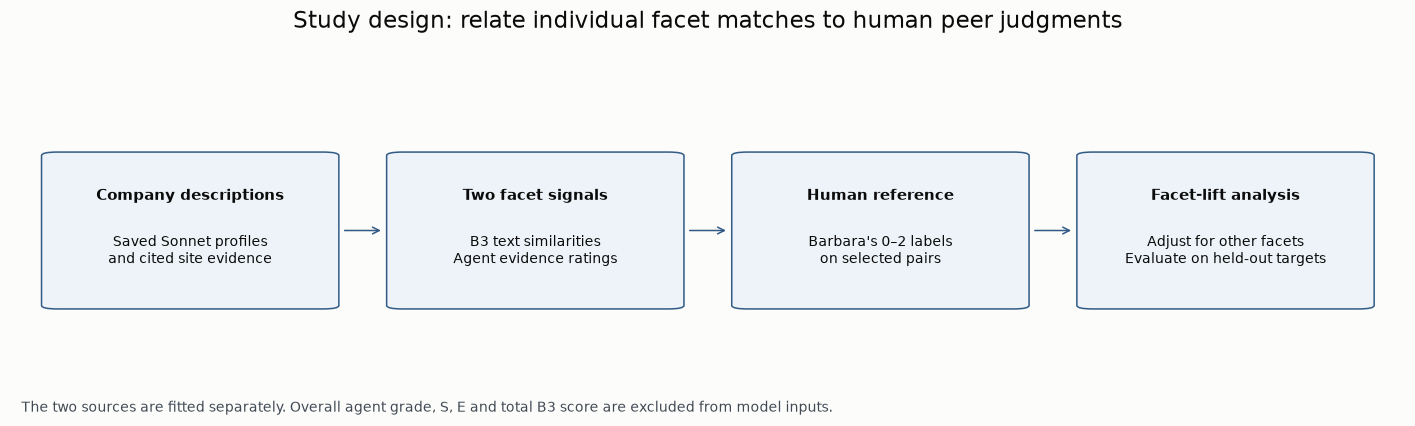

In [25]:
fig, ax = plt.subplots(figsize=(13,3.8)); ax.set(xlim=(-.025,1.025),ylim=(0,1)); ax.axis("off")
boxes=[(.01,"Company descriptions", "Saved Sonnet profiles\nand cited site evidence"),
       (.27,"Two facet signals", "B3 text similarities\nAgent evidence ratings"),
       (.53,"Human reference", "Barbara's 0–2 labels\non selected pairs"),
       (.79,"Facet-lift analysis", "Adjust for other facets\nEvaluate on held-out targets")]
for x,title,body in boxes:
    ax.add_patch(FancyBboxPatch((x,.24),.20,.52,boxstyle="round,pad=.012",facecolor="#edf3f8",edgecolor=BLUE))
    ax.text(x+.10,.62,title,ha="center",va="center",weight="bold",fontsize=10)
    ax.text(x+.10,.43,body,ha="center",va="center",fontsize=9)
for a,b in zip(boxes[:-1],boxes[1:]):
    ax.annotate("",xy=(b[0]-.014,.5),xytext=(a[0]+.214,.5),arrowprops={"arrowstyle":"->","color":BLUE})
fig.suptitle("Study design: relate individual facet matches to human peer judgments",fontsize=15)
save(fig,"01_approach","The two sources are fitted separately. Overall agent grade, S, E and total B3 score are excluded from model inputs.")

### The original human labels remain available

The full dataset contains **0 = non-peer, 1 = adjacent peer, 2 = direct peer**. Method A keeps these numerical values. Method B combines grades 1 and 2 only within its own outcome definition.

There is one reviewer (Barbara), and only 24 direct-peer labels. The pair list was selected from existing candidates and has already been used in pipeline development. It is not an untouched independent benchmark.

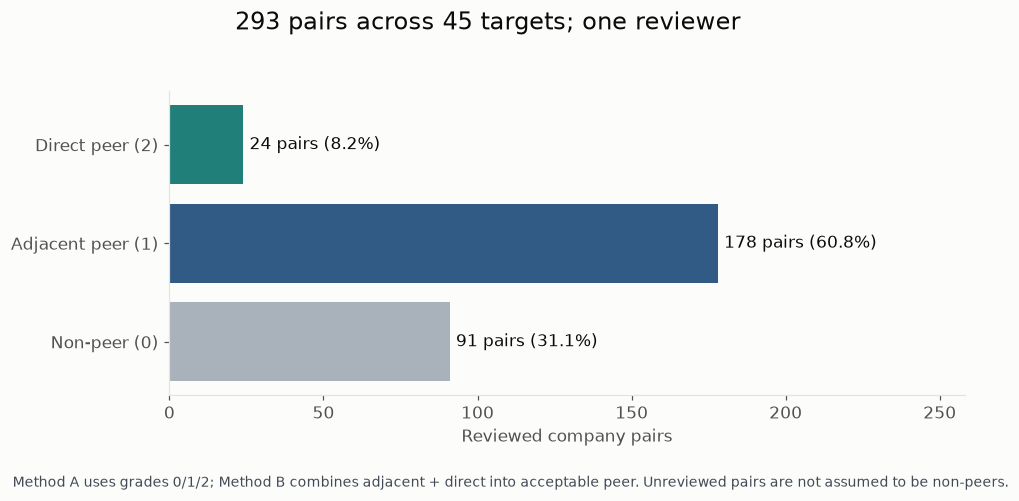

**Reading the cohort**  
202 of 293 pairs (68.9%) are acceptable peers. Only 24 are direct peers; Method A retains the grade distinctions, while Method B measures the combined peer outcome.

In [26]:
counts=features.grade.value_counts().reindex([0,1,2],fill_value=0)
fig,ax=plt.subplots(figsize=(9,4.5))
bars=ax.barh(["Non-peer (0)","Adjacent peer (1)","Direct peer (2)"],counts,color=[GRAY,BLUE,TEAL])
for bar,n in zip(bars,counts): ax.text(n+2,bar.get_y()+bar.get_height()/2,f"{n} pairs ({n/len(features):.1%})",va="center")
ax.set(xlim=(0,max(counts)*1.45),xlabel="Reviewed company pairs")
fig.suptitle(f"{len(features)} pairs across {features.target.nunique()} targets; one reviewer",fontsize=16)
save(fig,"02_review_cohort","Method A uses grades 0/1/2; Method B combines adjacent + direct into acceptable peer. Unreviewed pairs are not assumed to be non-peers.")
block("Reading the cohort",f"{int(counts[1]+counts[2])} of {len(features)} pairs ({(counts[1]+counts[2])/len(features):.1%}) are acceptable peers. Only {int(counts[2])} are direct peers; Method A retains the grade distinctions, while Method B measures the combined peer outcome.")

### Shared comparison and target validation

The **treatment stays binary in both methods**: stronger vs weaker match on one facet. Only the outcome and its response model change.

- Primary B3 contrast: above vs at/below the training median. Stricter: upper vs lower third, omitting the middle.
- Primary agent contrast: 75/100 vs 0/25/50. Stricter: 75/100 vs 0/25, omitting 50. Unknown is always missing.

Both analyses use five outer groups of target companies and three inner target groups for pseudo-effects. Each outer target is held out once; each training target has equal total weight. Median imputation, missingness indicators and scaling are fitted within training. At least 15 rows across five targets per arm are required. Summaries retain estimated propensities 0.1–0.9, then weight retained targets equally.

A comp company can occur in more than one target group. The experiment assesses held-out targets in the shared company universe, not entirely unseen entities.

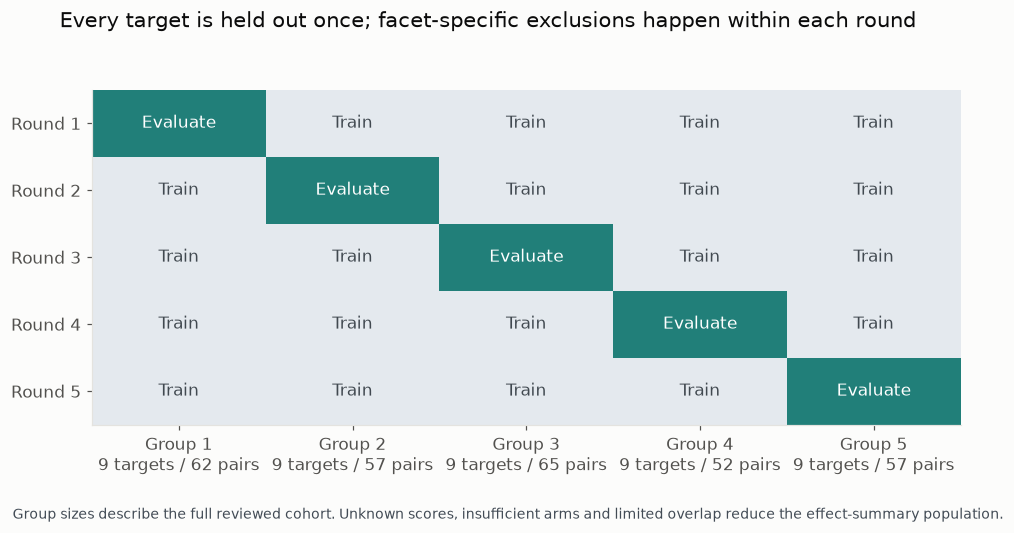

In [27]:
from facet_uplift import group_splits  # v1a: 09_analysis/scripts (on the path via paths.setup())
splits=list(group_splits(features.target.to_numpy()))
fig,ax=plt.subplots(figsize=(9,4.8))
ax.imshow(np.eye(5),cmap=ListedColormap(["#e4e9ee",TEAL]),vmin=0,vmax=1,aspect="auto")
for i,(train,test) in enumerate(splits):
    for j in range(5):
        ax.text(j,i,"Evaluate" if i==j else "Train",ha="center",va="center",color="white" if i==j else "#414950")
ax.set_xticks(range(5),[f"Group {i+1}\n{features.iloc[te].target.nunique()} targets / {len(te)} pairs" for i,(_,te) in enumerate(splits)])
ax.set_yticks(range(5),[f"Round {i+1}" for i in range(5)])
fig.suptitle("Every target is held out once; facet-specific exclusions happen within each round",fontsize=14)
save(fig,"03_target_validation","Group sizes describe the full reviewed cohort. Unknown scores, insufficient arms and limited overlap reduce the effect-summary population.")

### How the X-learner operates in both analyses

1. Fit separate expected-outcome models on strong and weak training pairs.
2. Impute the alternative outcome using models trained on other target groups: D1 = observed outcome − predicted weak-match outcome; D0 = predicted strong-match outcome − observed outcome.
3. Fit two ridge regressions to these imputed effects.
4. Combine their predictions with an estimated strong-match propensity: e(X) × effect model 0 + (1 − e(X)) × effect model 1.

The propensity model is logistic in both methods; ridge effect regressions use alpha=10. There are no observed true effect labels. We can evaluate response prediction on held-out human labels, but that does not directly validate the accuracy of estimated lift.

All uncertainty plots bootstrap targets with fitted predictions held fixed. They omit refitting, reviewer, threshold and candidate-selection uncertainty; they are not full causal confidence intervals or multiple-testing-adjusted significance tests.

In [28]:
def plot_effects(mode):
    s=DATA[mode]['facet_summary']; s=s[s.rule.eq('primary')]
    factor=1 if mode=='rating' else 100
    unit='rating points' if mode=='rating' else 'percentage points'
    values=s[['uplift_ci_low','uplift_ci_high']].to_numpy(float)*factor
    lo=min(0.,np.nanmin(values)); hi=max(0.,np.nanmax(values)); width=max(hi-lo,.1)
    left=lo-.12*width; right=hi+.10*width; count_x=right+.05*width
    fig,axes=plt.subplots(1,2,figsize=(15,7.3),sharex=True)
    for ax,source in zip(axes,['b3','agent']):
        part=s[s.source.eq(source)].sort_values('mean_uplift',ascending=False,na_position='last').reset_index(drop=True)
        for i,r in part.iterrows():
            if pd.notna(r.mean_uplift):
                color=BLUE if r.status=='complete' else ORANGE
                ax.plot([factor*r.uplift_ci_low,factor*r.uplift_ci_high],[i,i],color=color,lw=2)
                ax.scatter(factor*r.mean_uplift,i,color=color,zorder=3)
                ax.text(count_x,i,f'{int(r.overlap_pairs)} pairs / {int(r.overlap_targets)} targets',va='center',fontsize=8)
            else: ax.text(.01*width,i,'Insufficient support',va='center',fontsize=9,color='#606870')
        ax.set_yticks(range(len(part)),[NAMES[f] for f in part.facet]);ax.set_ylim(len(part)-.5,-.5)
        ax.set_xlim(left,right+.85*width);ax.axvline(0,color=GRAY,lw=.8)
        step=.2 if mode=='rating' else 10
        ax.set_xticks(np.arange(np.ceil(left/step)*step,right+1e-9,step))
        ax.set(title=source.upper(),xlabel=f'Estimated adjusted lift ({unit})')
    label={'rating':'A: original 0/1/2 rating','peer':'B: combined peer/non-peer',
           'selector':'C: selector keep (all 2,538 B3 pairs)'}[mode]  # v1a: Method C
    fig.suptitle(f'Method {label} — primary estimates',fontsize=15)
    save(fig,f'{mode}_primary_effects','Ranges hold predictions fixed; orange = incomplete evaluation rounds. Source contrasts/populations differ. No causal identification.')

def plot_sensitivity(mode):
    s=DATA[mode]['facet_summary']; factor=1 if mode=='rating' else 100
    unit='rating points' if mode=='rating' else 'percentage points'
    vals=s.mean_uplift.dropna().to_numpy()*factor
    lo=min(0.,vals.min());hi=max(0.,vals.max());width=max(hi-lo,.1)
    fig,axes=plt.subplots(1,2,figsize=(15,7),sharex=True)
    for ax,source in zip(axes,['b3','agent']):
        names=sorted(s.loc[s.source.eq(source),'facet'].unique())
        for i,f in enumerate(names):
            a,b=result_row(mode,source,f),result_row(mode,source,f,'extreme')
            if pd.isna(a.mean_uplift) or pd.isna(b.mean_uplift):
                ax.text(.01*width,i,'Insufficient support',va='center',fontsize=9,color='#606870');continue
            ax.plot([factor*a.mean_uplift,factor*b.mean_uplift],[i,i],color=GRAY)
            ax.scatter(factor*a.mean_uplift,i,color=BLUE,s=30);ax.scatter(factor*b.mean_uplift,i,color=TEAL,s=30)
            ax.text(hi+.14*width,i,f'{int(a.overlap_pairs)} → {int(b.overlap_pairs)} pairs',va='center',fontsize=8)
        ax.set_yticks(range(len(names)),[NAMES[f] for f in names]);ax.set_ylim(len(names)-.5,-.5)
        ax.set_xlim(lo-.12*width,hi+.85*width);ax.axvline(0,color=GRAY,lw=.8)
        step=.1 if mode=='rating' else 10
        ax.set_xticks(np.arange(np.ceil((lo-.12*width)/step)*step,hi+.07*width+1e-9,step))
        ax.set(title=source.upper(),xlabel=f'Estimated adjusted lift ({unit})')
    from matplotlib.lines import Line2D
    fig.legend(handles=[Line2D([],[],marker='o',linestyle='',color=BLUE,label='Primary'),Line2D([],[],marker='o',linestyle='',color=TEAL,label='Stricter')],loc='upper center',bbox_to_anchor=(.5,.94),ncol=2,frameon=False)
    fig.suptitle(f"{'Rating' if mode=='rating' else 'Combined binary'} outcome: sensitivity to match definition",fontsize=15)
    save(fig,f'{mode}_sensitivity','Stricter contrasts change both the match definition and included pairs. Counts are primary → stricter retained cases; not new observations.')

def show_findings(mode):
    s=DATA[mode]['facet_summary'];p=s[s.rule.eq('primary')]
    for source in ['b3','agent']:
        complete=p[p.source.eq(source)&p.status.eq('complete')].sort_values('mean_uplift',ascending=False)
        text='; '.join(f'{NAMES[r.facet]} {effect_text(r.mean_uplift,mode)}' for _,r in complete.head(4).iterrows())
        block(f'{source.upper()}: largest complete primary estimates',text+'. Descriptive ordering, not a proven ranking of facet importance.')
    display(p[['source','facet','status','folds_ok','overlap_pairs','overlap_targets','mean_uplift','uplift_ci_low','uplift_ci_high']].rename(columns={'mean_uplift':'Estimated lift','uplift_ci_low':'Fixed-prediction lower','uplift_ci_high':'Fixed-prediction upper'}).round(3))


<a id="method-a"></a>
### Method A — original 0/1/2 human rating

**Question:** is a stronger facet match associated with a higher expected human rating, using the distinction between non-peer, adjacent and direct?

**Outcome:** the original numerical score: 0, 1, or 2. We fit separate ridge response models (alpha=10) to each treatment arm and bound their expected-rating predictions to [0,2]. Effect models remain ridge regressions; the binary propensity model and all folds, feature inputs, treatment definitions and support rules are unchanged.

**Units:** a lift of **+0.25 rating points** is a difference in expected rating. It does not mean +25 percentage points or that every pair gains a quarter of a category.

**Assumption:** 0→1 and 1→2 are equally spaced. This is a numerical-score analysis, not a multiclass model estimating separate probabilities of 0, 1 and 2. It includes direct-peer information, but does not specifically isolate the probability of a direct peer.

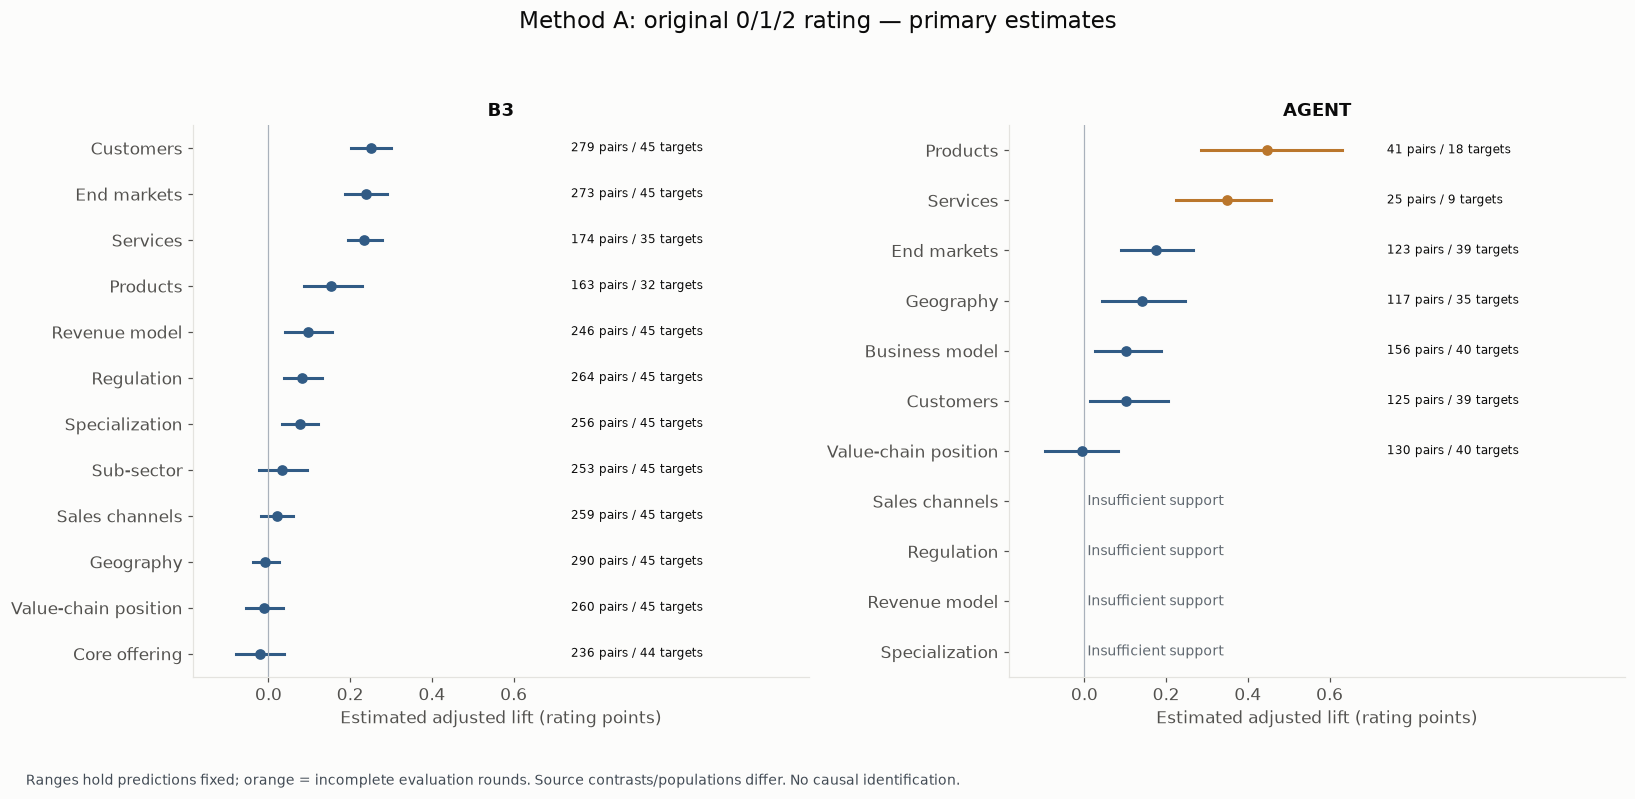

**B3: largest complete primary estimates**  
Customers +0.251 rating points; End markets +0.239 rating points; Services +0.234 rating points; Products +0.153 rating points. Descriptive ordering, not a proven ranking of facet importance.

**AGENT: largest complete primary estimates**  
End markets +0.175 rating points; Geography +0.140 rating points; Business model +0.102 rating points; Customers +0.101 rating points. Descriptive ordering, not a proven ranking of facet importance.

,source,facet,status,folds_ok,overlap_pairs,overlap_targets,Estimated lift,Fixed-prediction lower,Fixed-prediction upper
1,agent,business_model,complete,5,156.0,40.0,0.102,0.026,0.187
3,agent,customer_segment,complete,5,125.0,39.0,0.101,0.014,0.205
5,agent,distribution_channels,partial_or_unsupported,0,NaN,NaN,NaN,NaN,NaN
7,agent,end_markets,complete,5,123.0,39.0,0.175,0.091,0.266
9,agent,geography_served,complete,5,117.0,35.0,0.140,0.044,0.246
11,agent,primary_products,partial_or_unsupported,4,41.0,18.0,0.446,0.286,0.631
13,agent,primary_services,partial_or_unsupported,3,25.0,9.0,0.349,0.223,0.457
15,agent,regulatory_exposure,partial_or_unsupported,0,NaN,NaN,NaN,NaN,NaN
17,agent,revenue_model,partial_or_unsupported,0,NaN,NaN,NaN,NaN,NaN
19,agent,specialization,partial_or_unsupported,0,NaN,NaN,NaN,NaN,NaN


In [29]:
plot_effects('rating')
show_findings('rating')

### Method A — sensitivity and interpretation

We repeat the rating analysis with the stricter match definition. A positive direction under both comparisons is a useful hypothesis, not proof of a facet's causal importance. Partial agent results should be read with their small retained samples and incomplete rounds.

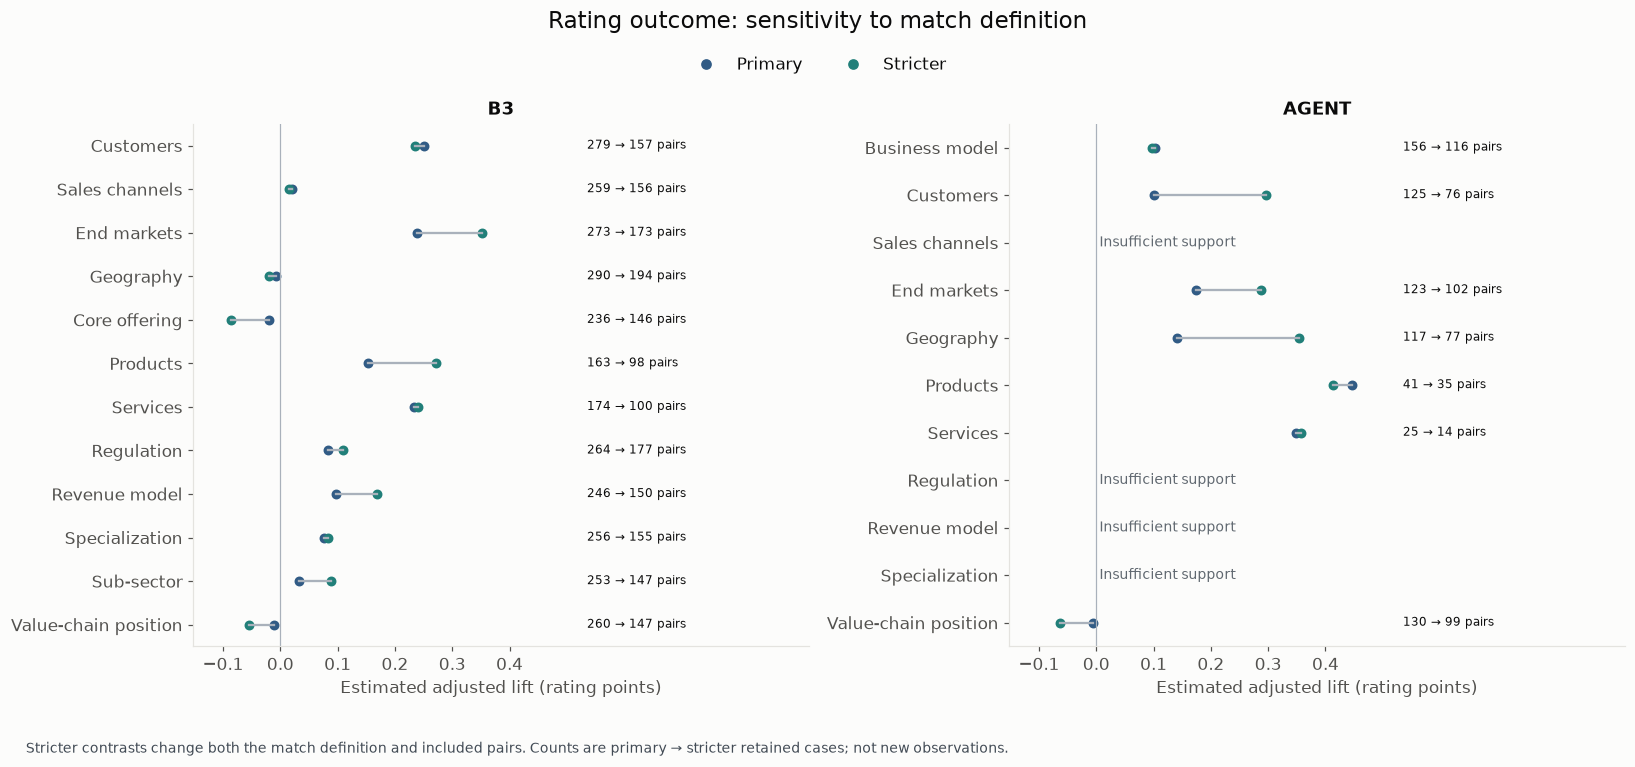

mean_uplift         overlap_pairs         folds_ok        
rule                                  extreme primary       extreme primary  extreme primary
source      facet                                                                           
agent       business_model              0.098   0.102         116.0   156.0      5.0     5.0
            customer_segment            0.296   0.101          76.0   125.0      5.0     5.0
            distribution_channels         NaN     NaN           NaN     NaN      0.0     0.0
            end_markets                 0.287   0.175         102.0   123.0      5.0     5.0
            geography_served            0.354   0.140          77.0   117.0      5.0     5.0
            primary_products            0.412   0.446          35.0    41.0      4.0     4.0
            primary_services            0.358   0.349          14.0    25.0      3.0     3.0
            regulatory_exposure           NaN     NaN           NaN     NaN      0.0     0.0
            revenue_model                 NaN     NaN           NaN     NaN      0.0     0.0
            specialization                NaN     NaN           NaN     NaN      0.0     0.0
            value_chain_position       -0.063  -0.005          99.0   130.0      5.0     5.0
agent_grade peer                          NaN   0.459           NaN   215.0      NaN     5.0
b3          customer_segment            0.234   0.251         157.0   279.0      5.0     5.0
            distribution_channels       0.015   0.021         156.0   259.0      5.0     5.0
            end_markets                 0.352   0.239         173.0   273.0      5.0     5.0
            geography_served           -0.020  -0.008         194.0   290.0      5.0     5.0
            offering_description       -0.086  -0.020         146.0   236.0      5.0     5.0
            primary_products            0.272   0.153          98.0   163.0      5.0     5.0
            primary_services            0.241   0.234         100.0   174.0      5.0     5.0
            regulatory_exposure         0.110   0.083         177.0   264.0      5.0     5.0
            revenue_model               0.168   0.097         150.0   246.0      5.0     5.0
            specialization              0.083   0.077         155.0   256.0      5.0     5.0
            sub_sector                  0.089   0.033         147.0   253.0      5.0     5.0
            value_chain_position       -0.055  -0.010         147.0   260.0      5.0     5.0
selector    keep                          NaN   0.146           NaN   120.0      NaN     5.0

In [30]:
plot_sensitivity('rating')
s=DATA['rating']['facet_summary']
display(s.pivot(index=['source','facet'],columns='rule',values=['mean_uplift','overlap_pairs','folds_ok']).round(3))

### Method A — how well are held-out ratings predicted?

**MAE** is the average absolute error in rating points; lower is better. **RMSE** gives larger mistakes more weight. The baseline always predicts the target-weighted average rating from the training fold.

These are outcome-prediction diagnostics, not measurements of true facet-effect accuracy. They use pair-weighted errors, whereas the lift summary weights retained targets equally. DR is a separate adjusted diagnostic, not effect ground truth.

In [31]:
s=DATA['rating']['facet_summary'];p=s[s.rule.eq('primary')]
display(p[['source','facet','mae','baseline_mae','rmse','baseline_rmse','dr_adjusted_difference','outside_rating_effect_range']].round(3))
r=result_row('rating','agent','customer_segment')
block('Rating-method sensitivity concern',f"Agent customers: X-learner {effect_text(r.mean_uplift,'rating')}; DR diagnostic {effect_text(r.dr_adjusted_difference,'rating')}. The opposite signs warrant case review.")


,source,facet,mae,baseline_mae,rmse,baseline_rmse,dr_adjusted_difference,outside_rating_effect_range
1,agent,business_model,0.365,0.479,0.463,0.582,0.036,0.0
3,agent,customer_segment,0.369,0.511,0.447,0.605,-0.106,0.0
5,agent,distribution_channels,NaN,NaN,NaN,NaN,NaN,NaN
7,agent,end_markets,0.382,0.484,0.459,0.581,0.121,0.0
9,agent,geography_served,0.363,0.474,0.445,0.606,0.180,0.0
11,agent,primary_products,0.387,0.448,0.477,0.555,0.320,1.0
13,agent,primary_services,0.368,0.445,0.460,0.549,0.271,0.0
15,agent,regulatory_exposure,NaN,NaN,NaN,NaN,NaN,NaN
17,agent,revenue_model,NaN,NaN,NaN,NaN,NaN,NaN
19,agent,specialization,NaN,NaN,NaN,NaN,NaN,NaN


**Rating-method sensitivity concern**  
Agent customers: X-learner +0.101 rating points; DR diagnostic -0.106 rating points. The opposite signs warrant case review.

<a id="method-b"></a>
### Method B — combined peer/non-peer (earlier analysis)

**Question:** is a stronger facet match associated with a greater chance that the reviewer accepts the pair as at least an adjacent peer?

**Outcome:** grade 0 becomes 0 (non-peer); grades 1 and 2 both become 1 (acceptable peer). This method deliberately treats adjacent and direct labels alike.

The response models are regularized logistic regressions (C=0.1), predicting peer probabilities. Ridge effect models, logistic propensity, treatment definitions, target folds and support rules follow the shared setup.

**Units:** estimates are shown in percentage points. +20 points means an estimated probability difference of 0.20; it is not +0.20 original-rating points or 20% more comps returned.

This remains the original saved binary experiment. Its numerical results are preserved, not refitted for this presentation.

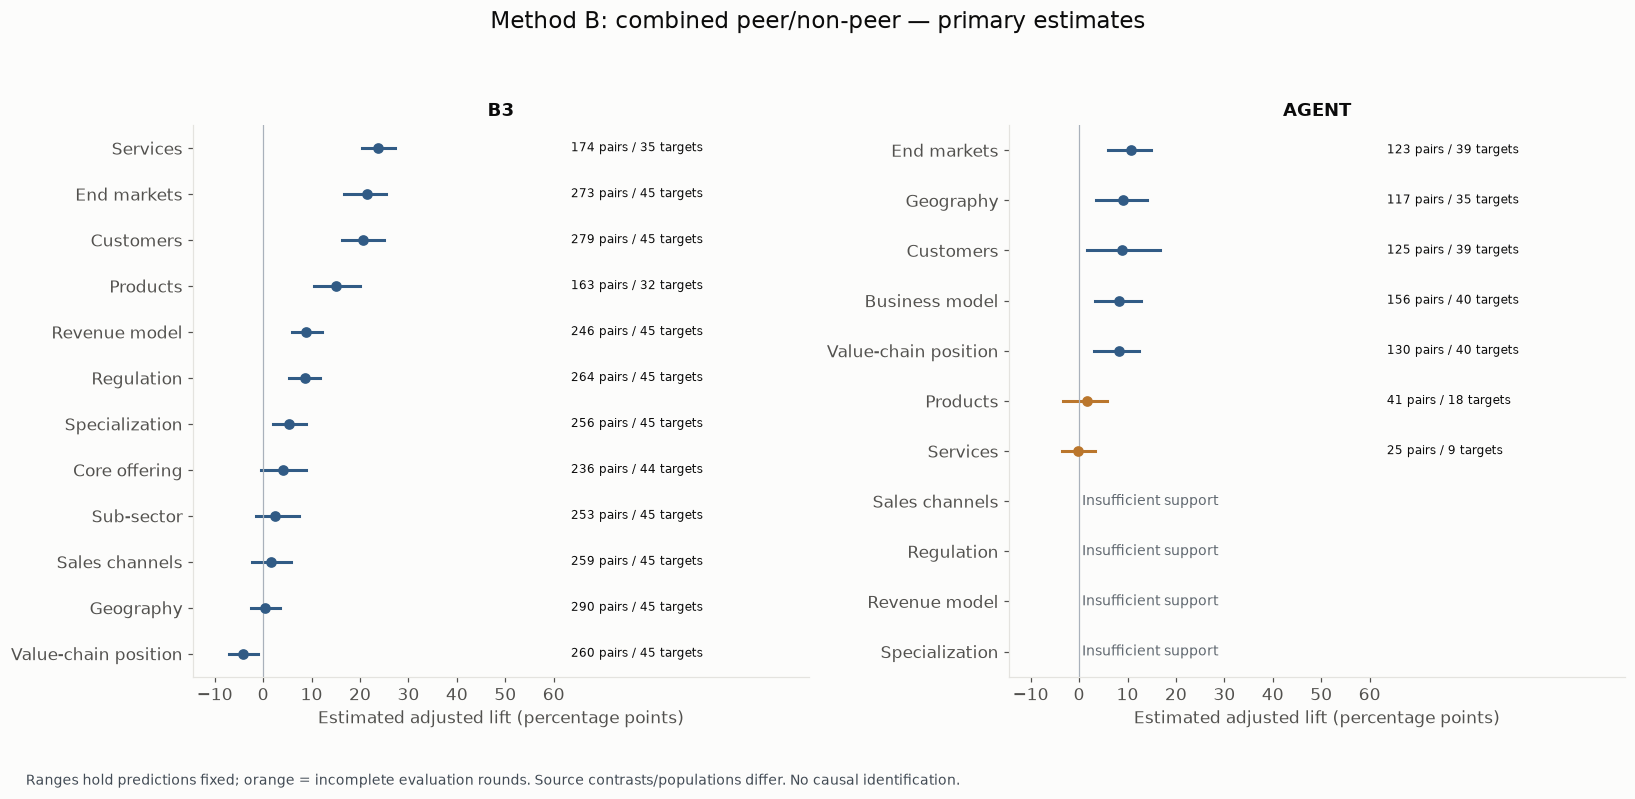

**B3: largest complete primary estimates**  
Services +23.8 percentage points; End markets +21.4 percentage points; Customers +20.7 percentage points; Products +15.1 percentage points. Descriptive ordering, not a proven ranking of facet importance.

**AGENT: largest complete primary estimates**  
End markets +10.7 percentage points; Geography +9.0 percentage points; Customers +8.9 percentage points; Business model +8.3 percentage points. Descriptive ordering, not a proven ranking of facet importance.

,source,facet,status,folds_ok,overlap_pairs,overlap_targets,Estimated lift,Fixed-prediction lower,Fixed-prediction upper
1,agent,business_model,complete,5,156.0,40.0,0.083,0.033,0.128
3,agent,customer_segment,complete,5,125.0,39.0,0.089,0.016,0.168
5,agent,distribution_channels,partial_or_unsupported,0,NaN,NaN,NaN,NaN,NaN
7,agent,end_markets,complete,5,123.0,39.0,0.107,0.059,0.149
9,agent,geography_served,complete,5,117.0,35.0,0.090,0.036,0.140
11,agent,primary_products,partial_or_unsupported,4,41.0,18.0,0.016,-0.033,0.057
13,agent,primary_services,partial_or_unsupported,3,25.0,9.0,-0.002,-0.036,0.033
15,agent,regulatory_exposure,partial_or_unsupported,0,NaN,NaN,NaN,NaN,NaN
17,agent,revenue_model,partial_or_unsupported,0,NaN,NaN,NaN,NaN,NaN
19,agent,specialization,partial_or_unsupported,0,NaN,NaN,NaN,NaN,NaN


In [32]:
plot_effects('peer')
show_findings('peer')

### Method B — sensitivity and interpretation

The stricter binary analysis changes the match contrast and the included population. Its estimates still describe the probability of any acceptable peer rating, with no distinction between adjacent and direct peers.

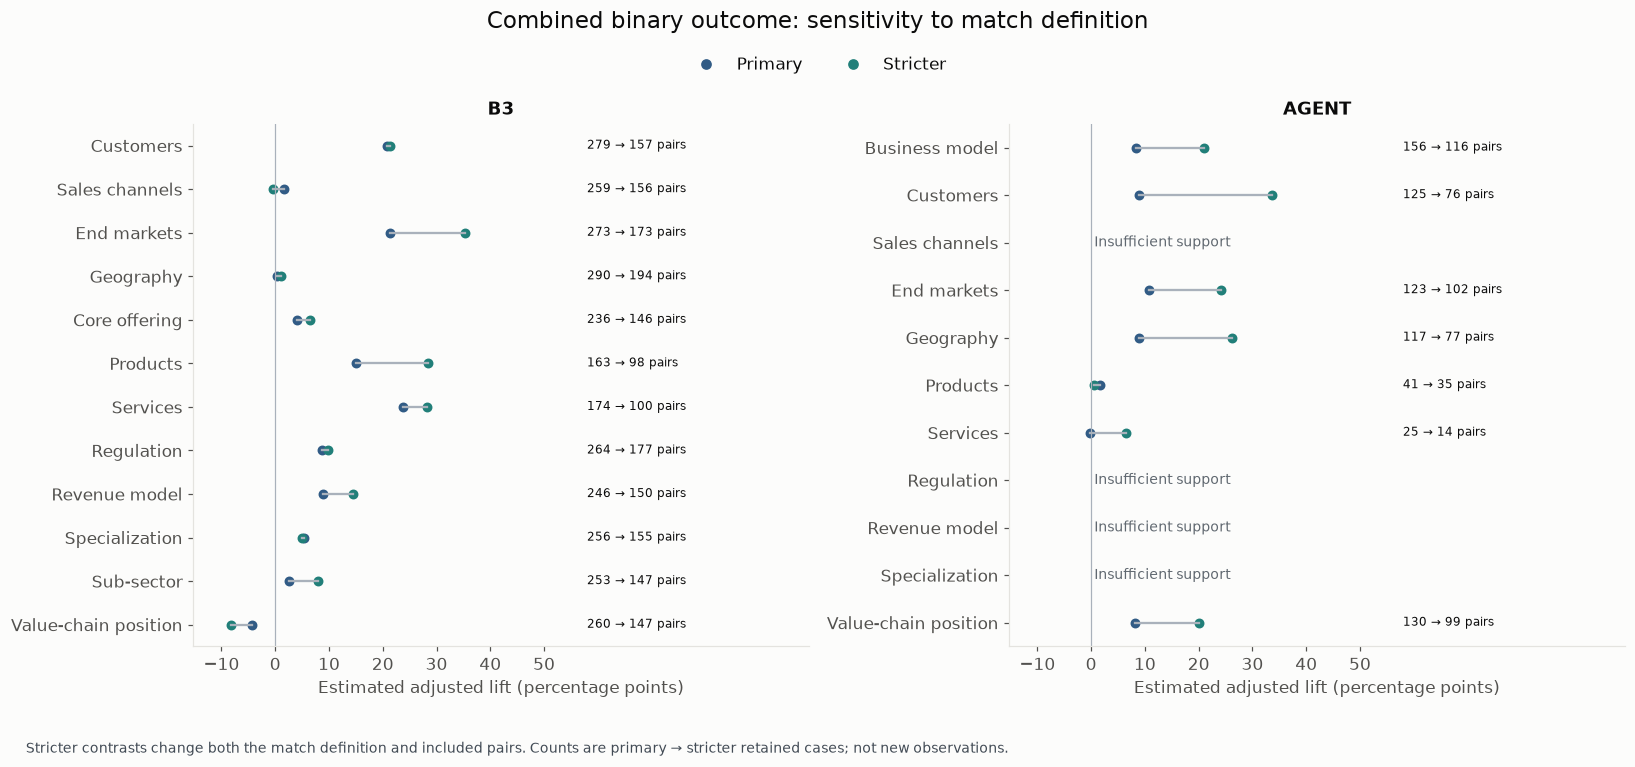

mean_uplift         overlap_pairs         folds_ok        
rule                                  extreme primary       extreme primary  extreme primary
source      facet                                                                           
agent       business_model              0.209   0.083         116.0   156.0      5.0     5.0
            customer_segment            0.336   0.089          76.0   125.0      5.0     5.0
            distribution_channels         NaN     NaN           NaN     NaN      0.0     0.0
            end_markets                 0.241   0.107         102.0   123.0      5.0     5.0
            geography_served            0.263   0.090          77.0   117.0      5.0     5.0
            primary_products            0.006   0.016          35.0    41.0      4.0     4.0
            primary_services            0.066  -0.002          14.0    25.0      3.0     3.0
            regulatory_exposure           NaN     NaN           NaN     NaN      0.0     0.0
            revenue_model                 NaN     NaN           NaN     NaN      0.0     0.0
            specialization                NaN     NaN           NaN     NaN      0.0     0.0
            value_chain_position        0.201   0.082          99.0   130.0      5.0     5.0
agent_grade peer                          NaN   0.499           NaN   215.0      NaN     5.0
b3          customer_segment            0.214   0.207         157.0   279.0      5.0     5.0
            distribution_channels      -0.004   0.016         156.0   259.0      5.0     5.0
            end_markets                 0.353   0.214         173.0   273.0      5.0     5.0
            geography_served            0.011   0.004         194.0   290.0      5.0     5.0
            offering_description        0.065   0.041         146.0   236.0      5.0     5.0
            primary_products            0.284   0.151          98.0   163.0      5.0     5.0
            primary_services            0.282   0.238         100.0   174.0      5.0     5.0
            regulatory_exposure         0.098   0.087         177.0   264.0      5.0     5.0
            revenue_model               0.144   0.089         150.0   246.0      5.0     5.0
            specialization              0.049   0.053         155.0   256.0      5.0     5.0
            sub_sector                  0.079   0.025         147.0   253.0      5.0     5.0
            value_chain_position       -0.083  -0.043         147.0   260.0      5.0     5.0
selector    keep                          NaN   0.040           NaN   120.0      NaN     5.0

In [33]:
plot_sensitivity('peer')
s=DATA['peer']['facet_summary']
display(s.pivot(index=['source','facet'],columns='rule',values=['mean_uplift','overlap_pairs','folds_ok']).round(3))

### Method B — how well are held-out peer probabilities predicted?

Brier loss measures probability error; lower is better. AUC assesses discrimination between acceptable peers and non-peers. The baseline is the target-weighted average binary outcome from training.

Neither metric establishes the accuracy of estimated facet lift. Brier/AUC cannot be directly compared to Method A's MAE/RMSE, which assess a different outcome on a different scale.

In [34]:
s=DATA['peer']['facet_summary'];p=s[s.rule.eq('primary')]
display(p[['source','facet','brier','baseline_brier','response_auc','dr_adjusted_difference','outside_probability_range']].round(3))
r=result_row('peer','agent','customer_segment')
block('Binary-method sensitivity concern',f"Agent customers: X-learner {effect_text(r.mean_uplift,'peer')}; DR diagnostic {effect_text(r.dr_adjusted_difference,'peer')}. The methods disagree on the sign here as well.")

,source,facet,brier,baseline_brier,response_auc,dr_adjusted_difference,outside_probability_range
1,agent,business_model,0.153,0.213,0.803,0.030,1.0
3,agent,customer_segment,0.136,0.220,0.865,-0.031,5.0
5,agent,distribution_channels,NaN,NaN,NaN,NaN,NaN
7,agent,end_markets,0.143,0.214,0.853,0.107,3.0
9,agent,geography_served,0.156,0.210,0.827,0.067,0.0
11,agent,primary_products,0.161,0.213,0.795,0.047,0.0
13,agent,primary_services,0.141,0.210,0.825,0.014,0.0
15,agent,regulatory_exposure,NaN,NaN,NaN,NaN,NaN
17,agent,revenue_model,NaN,NaN,NaN,NaN,NaN
19,agent,specialization,NaN,NaN,NaN,NaN,NaN


**Binary-method sensitivity concern**  
Agent customers: X-learner +8.9 percentage points; DR diagnostic -3.1 percentage points. The methods disagree on the sign here as well.

### Shared support limits: a missing estimate is not zero usefulness

Both outcome methods use the same observed facet scores and treatment groups, so support is the same: B3 has 12 complete primary analyses (11 in v1; v1a adds sub-sector); the agent has five complete, two partial and four unsupported. The chart below applies to both methods.

Products/services have only 20/19 strong agent matches in the full cohort, and their effect summaries retain 41/25 pairs. These are partial analyses, even when their rating-point estimates appear large. Revenue-model, regulation and channel evidence is mostly missing. More evidence and more balanced examples are needed before drawing conclusions.

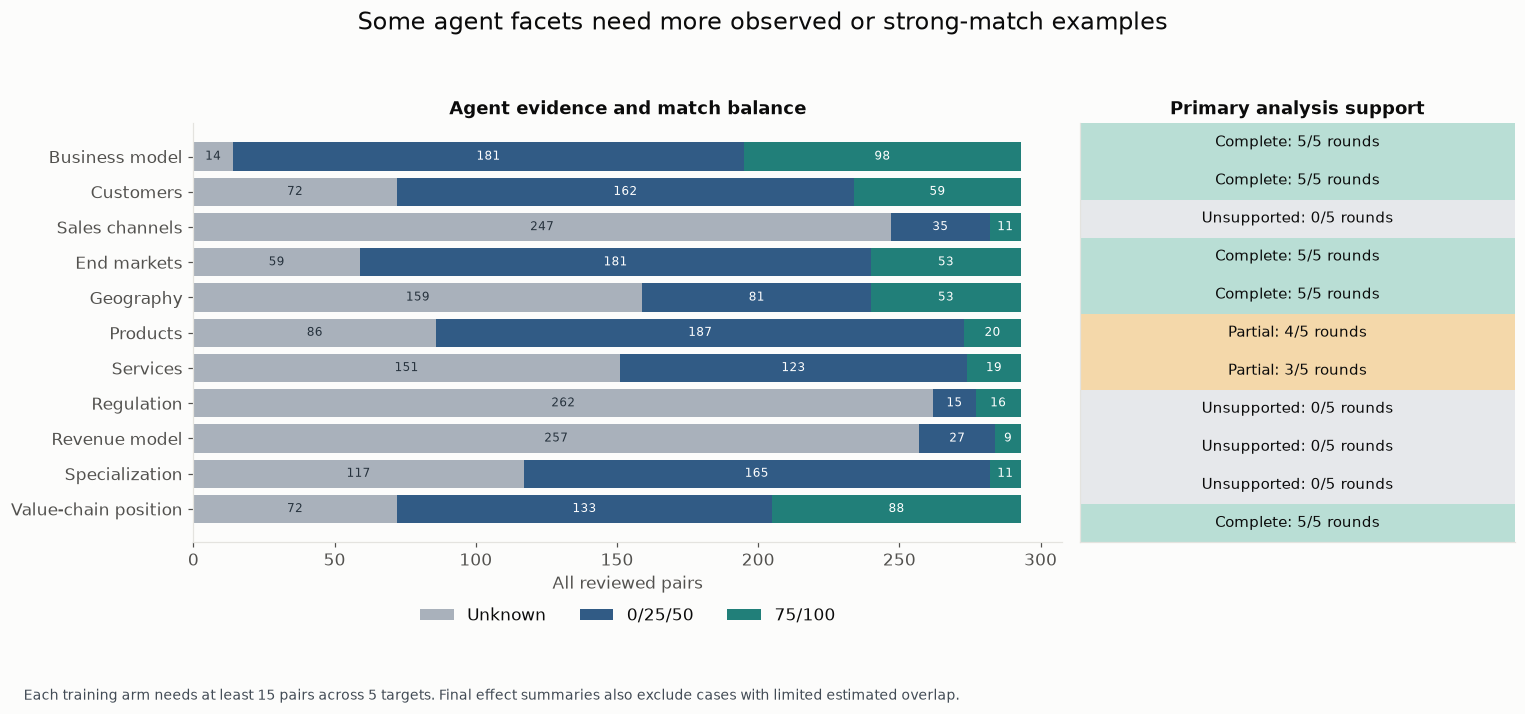

**Coverage finding**  
B3: 12 complete primary analyses. Agent: 5 complete, 2 partial, 4 unsupported. Products have only 20 strong-match pairs; services have 19. Revenue-model evidence is missing for 257 of 293 pairs.

In [35]:
part=primary[primary.source.eq("agent")].sort_values("facet").reset_index(drop=True)
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(14,6.5),gridspec_kw={"width_ratios":[2,1]})
y=np.arange(len(part));left=np.zeros(len(part))
for category,color,selector in [("Unknown",GRAY,lambda v:v.isna()),("0/25/50",BLUE,lambda v:v.le(50)),("75/100",TEAL,lambda v:v.ge(75))]:
    vals=np.array([int(selector(features['agent__'+f]).sum()) for f in part.facet])
    ax1.barh(y,vals,left=left,color=color,label=category)
    for i,(n,l) in enumerate(zip(vals,left)):
        if n>=9:ax1.text(l+n/2,i,str(n),ha="center",va="center",fontsize=8,color="white" if category!="Unknown" else "#26323d")
    left+=vals
ax1.set_yticks(y,[NAMES[f] for f in part.facet]);ax1.invert_yaxis();ax1.set(xlabel="All reviewed pairs",title="Agent evidence and match balance")
ax1.legend(loc="upper center",bbox_to_anchor=(.5,-.12),ncol=3,frameon=False)
status=np.array([[0 if r.folds_ok==0 else 1 if r.folds_ok<5 else 2] for _,r in part.iterrows()])
ax2.imshow(status,cmap=ListedColormap(["#e6e8eb","#f4d8aa","#b9ded5"]),vmin=0,vmax=2,aspect="auto")
for i,r in part.iterrows():
    label="Unsupported" if r.folds_ok==0 else "Partial" if r.folds_ok<5 else "Complete"
    ax2.text(0,i,f"{label}: {int(r.folds_ok)}/5 rounds",ha="center",va="center",fontsize=10)
ax2.set_yticks([]);ax2.set_xticks([]);ax2.set_title("Primary analysis support")
fig.suptitle("Some agent facets need more observed or strong-match examples",fontsize=16)
save(fig,"06_agent_support","Each training arm needs at least 15 pairs across 5 targets. Final effect summaries also exclude cases with limited estimated overlap.")
complete=int(part.status.eq("complete").sum()); partial=int(part.folds_ok.between(1,4).sum());unsupported=int(part.folds_ok.eq(0).sum())
b3_complete=int(primary[primary.source.eq("b3")].status.eq("complete").sum())  # v1a: was typed as 11
block("Coverage finding",f"B3: {b3_complete} complete primary analyses. Agent: {complete} complete, {partial} partial, {unsupported} unsupported. Products have only {int(features.agent__primary_products.ge(75).sum())} strong-match pairs; services have {int(features.agent__primary_services.ge(75).sum())}. Revenue-model evidence is missing for {int(features.agent__revenue_model.isna().sum())} of {len(features)} pairs.")

### Evidence availability by source (from Kethan's technical notebook)

`v1/notebooks/facet_uplift.ipynb` section 1: the share of unknown or not-applicable values per signal.

,signal,missing_fraction
0,agent__primary_products,0.293515
1,agent__primary_services,0.515358
2,agent__customer_segment,0.245734
3,agent__end_markets,0.201365
4,agent__business_model,0.047782
5,agent__revenue_model,0.877133
6,agent__value_chain_position,0.245734
7,agent__geography_served,0.542662
8,agent__specialization,0.399317
9,agent__distribution_channels,0.843003


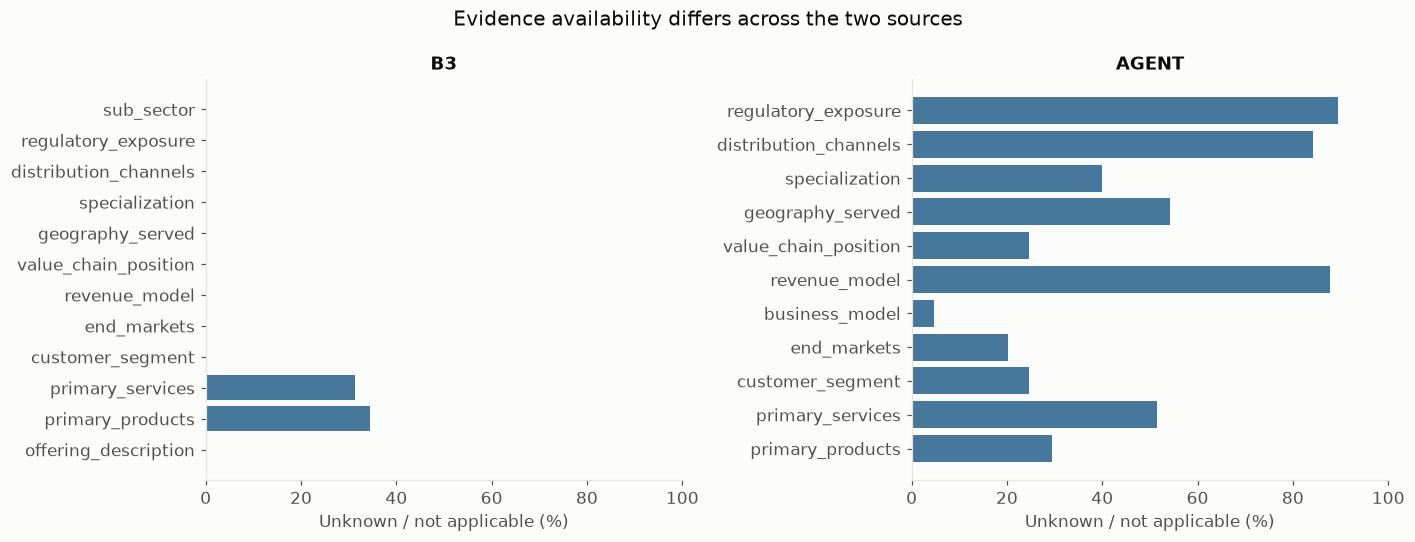

In [36]:
missing = features.filter(regex="^(b3|agent)__").isna().mean().rename("missing_fraction").rename_axis("signal").reset_index()
display(missing)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, source in zip(axes, ["b3", "agent"]):
    m = missing[missing.signal.str.startswith(source + "__")].copy()
    ax.barh(m.signal.str.split("__").str[1], 100*m.missing_fraction, color="#46789d")
    ax.set(title=source.upper(), xlabel="Unknown / not applicable (%)", xlim=(0, 100))
fig.suptitle("Evidence availability differs across the two sources")
fig.tight_layout()
fig.savefig(PRESENTATION / "missingness.png", dpi=160, bbox_inches="tight")  # v1a: with the other figures, not in the run folder
plt.show()

<a id="comparison"></a>
### How the findings differ — and what to investigate next

The following comparison keeps outcome units separate. Changing the outcome also changes the response estimator (logistic vs bounded ridge), so differences are not solely the effect of retaining labels. There is no single combined ranking across the two methods.

- **Core B3 priorities persist:** customers, end markets, services and products are positive under both outcome definitions and both tested match contrasts. Prioritize new reviewer labels and frozen pipeline ablations for these hypotheses.
- **Some findings depend on the question:** core offering and value-chain position change when assessing expected rating rather than any acceptable peer label. Check the specific pair cases instead of translating one method's score into the other's units.
- **Large partial agent estimates need restraint:** retaining 0/1/2 changes the product/service story, but does not create additional strong-match examples or independent targets. Treat these as data-collection hypotheses rather than new weights.
- **Independent review is still needed:** only 24 pairs are direct peers and all labels come from one reviewer. A second reviewer and additional targets are important for testing whether the findings generalize.

Neither analysis shows that changing facet weights improves B3 or B3 + agent review, and neither establishes causal CATE.

In [37]:
comparisons=[]
for source in ['b3','agent']:
    for facet in sorted(DATA['rating']['facet_summary'].query('source==@source').facet.unique()):
        a,b=result_row('rating',source,facet),result_row('peer',source,facet)
        comparisons.append({'Source':source,'Facet':NAMES[facet],
            'A: rating points':a.mean_uplift,'B: percentage points':100*b.mean_uplift,
            'Evaluation rounds':int(a.folds_ok),'Retained pairs':a.overlap_pairs})
display(pd.DataFrame(comparisons).round(3))
for source,facet in [('b3','offering_description'),('b3','value_chain_position'),('agent','primary_products'),('agent','primary_services'),('agent','value_chain_position')]:
    a,b=result_row('rating',source,facet),result_row('peer',source,facet)
    block(f'{source.upper()} {NAMES[facet]}',f"A: {effect_text(a.mean_uplift,'rating')}; B: {effect_text(b.mean_uplift,'peer')}. {int(a.folds_ok)}/5 rounds; {int(a.overlap_pairs)} retained pairs. Units and outcome models differ.")


,Source,Facet,A: rating points,B: percentage points,Evaluation rounds,Retained pairs
0,b3,Customers,0.251,20.708,5,279.0
1,b3,Sales channels,0.021,1.581,5,259.0
2,b3,End markets,0.239,21.354,5,273.0
3,b3,Geography,-0.008,0.387,5,290.0
4,b3,Core offering,-0.020,4.110,5,236.0
5,b3,Products,0.153,15.114,5,163.0
6,b3,Services,0.234,23.790,5,174.0
7,b3,Regulation,0.083,8.688,5,264.0
8,b3,Revenue model,0.097,8.929,5,246.0
9,b3,Specialization,0.077,5.259,5,256.0


**B3 Core offering**  
A: -0.020 rating points; B: +4.1 percentage points. 5/5 rounds; 236 retained pairs. Units and outcome models differ.

**B3 Value-chain position**  
A: -0.010 rating points; B: -4.3 percentage points. 5/5 rounds; 260 retained pairs. Units and outcome models differ.

**AGENT Products**  
A: +0.446 rating points; B: +1.6 percentage points. 4/5 rounds; 41 retained pairs. Units and outcome models differ.

**AGENT Services**  
A: +0.349 rating points; B: -0.2 percentage points. 3/5 rounds; 25 retained pairs. Units and outcome models differ.

**AGENT Value-chain position**  
A: -0.005 rating points; B: +8.2 percentage points. 5/5 rounds; 130 retained pairs. Units and outcome models differ.

### Method C: what does the selector keep on? (v1a)

**Question:** which facet matches does the LLM selector (04) act on? **Outcome:** the selector kept the comp (1) or
dropped it (0), on every pair of the current B3 lists (2,538 pairs, 373 training targets) and, for a like-for-like
comparison with Method B, on the same 293 pairs. Same estimator, treatments and support rules as Method B; the
outcome is the model's decision, not comp quality. Comparing B and C shows where the selector weighs a facet
differently from people.

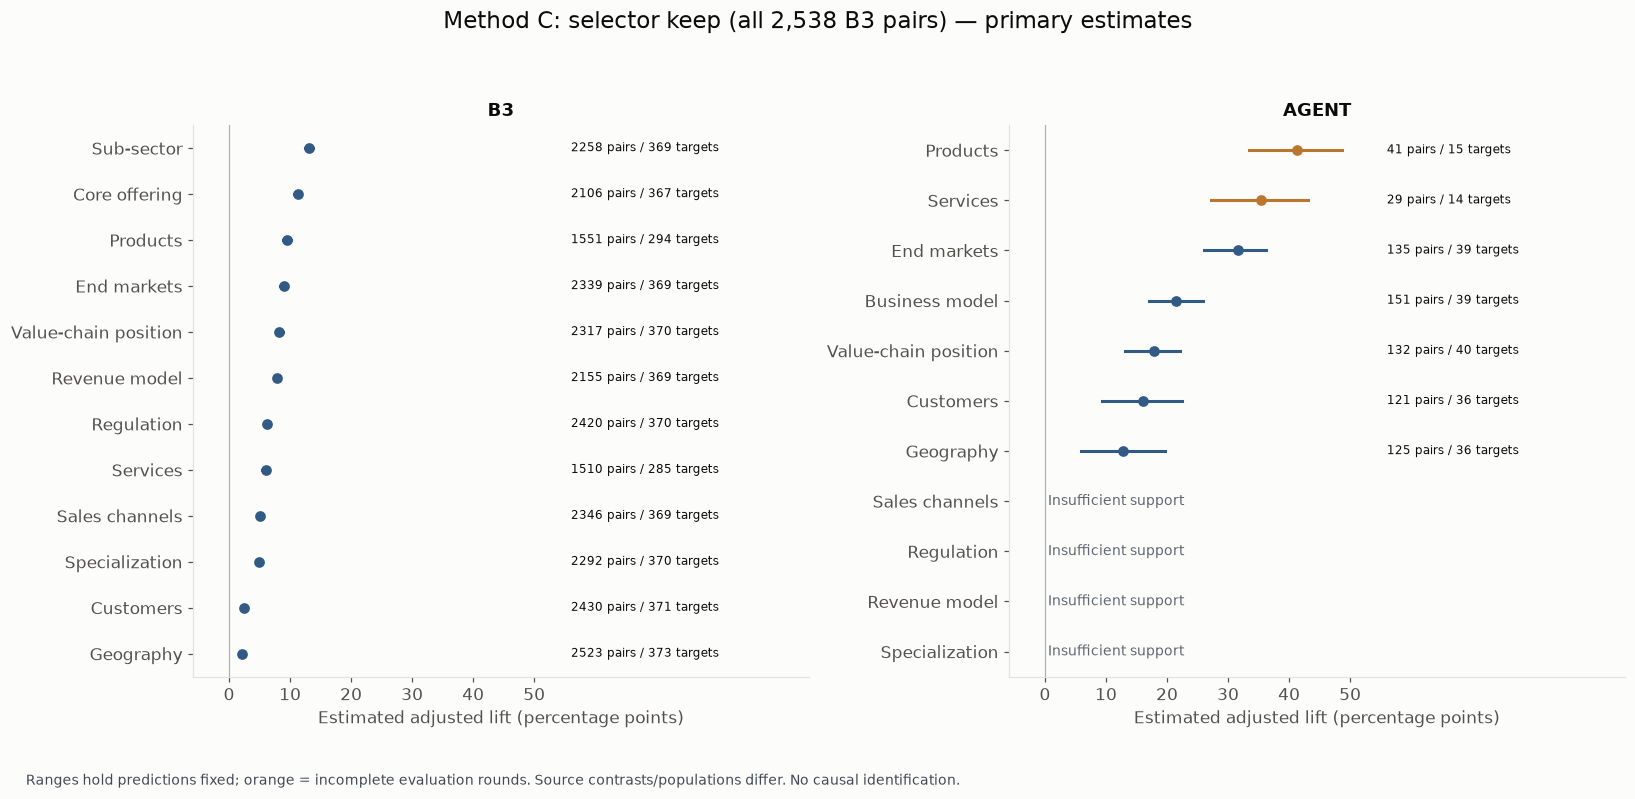

**B3: largest complete primary estimates**  
Sub-sector +13.2 percentage points; Core offering +11.3 percentage points; Products +9.4 percentage points; End markets +8.9 percentage points. Descriptive ordering, not a proven ranking of facet importance.

**AGENT: largest complete primary estimates**  
End markets +31.7 percentage points; Business model +21.4 percentage points; Value-chain position +17.9 percentage points; Customers +16.1 percentage points. Descriptive ordering, not a proven ranking of facet importance.

,source,facet,status,folds_ok,overlap_pairs,overlap_targets,Estimated lift,Fixed-prediction lower,Fixed-prediction upper
1,agent,business_model,complete,5,151.0,39.0,0.214,0.171,0.259
3,agent,customer_segment,complete,5,121.0,36.0,0.161,0.094,0.224
5,agent,distribution_channels,partial_or_unsupported,0,NaN,NaN,NaN,NaN,NaN
7,agent,end_markets,complete,5,135.0,39.0,0.317,0.261,0.363
9,agent,geography_served,complete,5,125.0,36.0,0.128,0.059,0.197
11,agent,primary_products,partial_or_unsupported,4,41.0,15.0,0.413,0.334,0.487
13,agent,primary_services,partial_or_unsupported,4,29.0,14.0,0.353,0.272,0.431
15,agent,regulatory_exposure,partial_or_unsupported,0,NaN,NaN,NaN,NaN,NaN
17,agent,revenue_model,partial_or_unsupported,0,NaN,NaN,NaN,NaN,NaN
19,agent,specialization,partial_or_unsupported,0,NaN,NaN,NaN,NaN,NaN


In [38]:
plot_effects('selector')
show_findings('selector')


People (Method B) vs the selector (Method C), B3 signals, percentage points. `selector (293)` is on the same pairs as `people (293)`. Complete five-fold analyses only.

In [39]:
t = fu.lift_table({"people (293)": runs["human_peer"], "selector (293)": runs["selector_293"],
                   "selector (2538)": runs["selector_all"]})
lift = (t.xs("lift", axis=1, level=1) * 100).round(1)
lift["people - selector (293)"] = (lift["people (293)"] - lift["selector (293)"]).round(1)
b3 = lift.loc["b3"].sort_values("people (293)", ascending=False)
b3

,people (293),selector (293),selector (2538),people - selector (293)
facet,,,,
primary_services,23.8,8.2,6.0,15.6
end_markets,21.4,10.6,8.9,10.8
customer_segment,20.7,6.7,2.5,14.0
primary_products,15.1,11.8,9.4,3.3
revenue_model,8.9,7.8,7.9,1.1
regulatory_exposure,8.7,7.3,6.2,1.4
specialization,5.3,8.3,4.9,-3.0
offering_description,4.1,14.6,11.3,-10.5
sub_sector,2.5,10.8,13.2,-8.3


In [40]:
ci = (t * 100).round(1)
ci.loc["b3"].sort_values(("people (293)", "lift"), ascending=False)

people (293)             selector (293)             selector (2538)            
                              lift   low  high           lift   low  high            lift   low  high
facet                                                                                                
primary_services              23.8  20.3  27.2            8.2   4.1  12.3             6.0   5.5   6.5
end_markets                   21.4  16.8  25.4           10.6   7.7  13.8             8.9   8.4   9.4
customer_segment              20.7  16.2  24.9            6.7   4.2   9.0             2.5   2.2   2.9
primary_products              15.1  10.5  19.9           11.8   6.9  17.1             9.4   8.8  10.2
revenue_model                  8.9   6.0  12.1            7.8   5.1  10.4             7.9   7.4   8.4
regulatory_exposure            8.7   5.4  11.7            7.3   5.2   9.4             6.2   5.7   6.7
specialization                 5.3   2.0   8.9            8.3   5.6  10.8             4.9   4.5   5.3
offering_description           4.1  -0.5   8.8           14.6  11.7  17.4            11.3  10.7  11.8
sub_sector                     2.5  -1.6   7.4           10.8   7.9  13.7            13.2  12.5  13.8
distribution_channels          1.6  -2.4   5.8            4.4   1.0   7.6             5.0   4.6   5.4
geography_served               0.4  -2.6   3.6            0.2  -1.5   1.7             2.0   1.7   2.4
value_chain_position          -4.3  -7.0  -1.1            2.0  -0.6   4.6             8.2   7.6   8.8

In [41]:
def strong(col, tab=t, src="b3"):
    x = tab.loc[src, col]
    return x[x["low"] > 0].sort_values("lift", ascending=False)
p, s = strong("people (293)"), strong("selector (2538)")
print("B3 facets that go with a human peer (interval above 0):", ", ".join(f"{f} {v*100:+.1f}" for f, v in p["lift"].items()))
print("B3 facets the selector keeps on (all 2,538 pairs):    ", ", ".join(f"{f} {v*100:+.1f}" for f, v in s["lift"].items()))
gap = b3["people - selector (293)"]
print("Under-used by the selector (people lift >> selector lift, same 293 pairs):",
      ", ".join(f"{f} {v:+.1f}" for f, v in gap[gap > 5].items()))
print("Over-used by the selector (selector lift >> people lift):",
      ", ".join(f"{f} {v:+.1f}" for f, v in gap[gap < -5].items()))

B3 facets that go with a human peer (interval above 0): primary_services +23.8, end_markets +21.4, customer_segment +20.7, primary_products +15.1, revenue_model +8.9, regulatory_exposure +8.7, specialization +5.3
B3 facets the selector keeps on (all 2,538 pairs):     sub_sector +13.2, offering_description +11.3, primary_products +9.4, end_markets +8.9, value_chain_position +8.2, revenue_model +7.9, regulatory_exposure +6.2, primary_services +6.0, distribution_channels +5.0, specialization +4.9, customer_segment +2.5, geography_served +2.0
Under-used by the selector (people lift >> selector lift, same 293 pairs): primary_services +15.6, end_markets +10.8, customer_segment +14.0
Over-used by the selector (selector lift >> people lift): offering_description -10.5, sub_sector -8.3, value_chain_position -6.3


### Stage ablation: what each LLM stage adds beyond the B3 facets (v1a)

The same estimator with a stage's decision as the treatment instead of one facet, adjusted for all 12 B3 signals:
`selector keep` = 04 kept the comp; `agent_grade peer` = 05 graded it 1 or 2 (the 3 pairs it left ungraded are out).
Dots and ranges as above; the orange cross is the doubly robust diagnostic of the same contrast. Where the two
disagree in sign (the selector), the estimate is fragile. The agent grades with the reviewers' rubric, so a large
lift is expected; the agent's ranking order was chosen on these labels.

In [42]:
rows = []
for name, unit, scale in (("human_peer", "pp of peer probability", 100), ("human_rating", "rating points (0-2)", 1)):
    summary = pd.read_csv(runs[name] / "facet_summary.csv").query("source in ['selector', 'agent_grade']")
    for _, s in summary.iterrows():
        rows.append({"stage": f"{s.source} {s.facet}", "outcome": name, "unit": unit,
                     "lift": round(s.mean_uplift * scale, 2), "low": round(s.uplift_ci_low * scale, 2),
                     "high": round(s.uplift_ci_high * scale, 2), "dr": round(s.dr_adjusted_difference * scale, 2),
                     "pairs": int(s.predicted_pairs), "overlap pairs": int(s.overlap_pairs), "folds ok": int(s.folds_ok)})
pd.DataFrame(rows)


,stage,outcome,unit,lift,low,high,dr,pairs,overlap pairs,folds ok
0,agent_grade peer,human_peer,pp of peer probability,49.85,45.21,54.35,48.33,290,215,5
1,selector keep,human_peer,pp of peer probability,3.99,0.07,7.59,-9.70,293,120,5
2,agent_grade peer,human_rating,rating points (0-2),0.46,0.40,0.51,0.45,290,215,5
3,selector keep,human_rating,rating points (0-2),0.15,0.07,0.22,-0.06,293,120,5


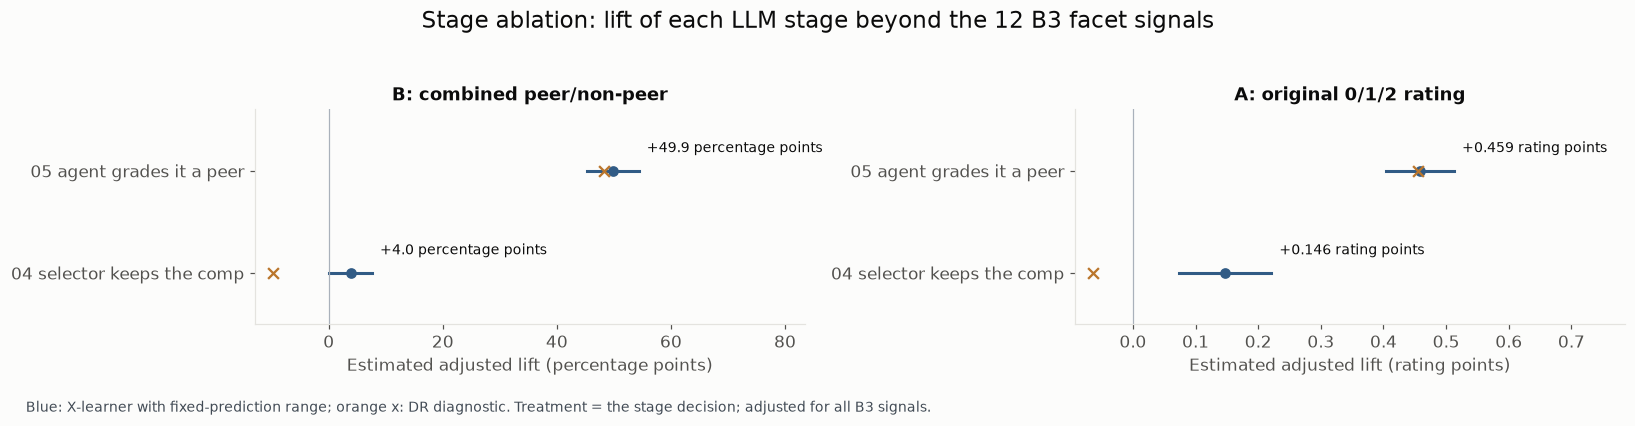

In [43]:
STAGES = {'keep':'04 selector keeps the comp','peer':'05 agent grades it a peer'}
fig,axes=plt.subplots(1,2,figsize=(15,3.8))
for ax,mode in zip(axes,['peer','rating']):
    factor=1 if mode=='rating' else 100
    s=DATA[mode]['facet_summary']; part=s[s.source.isin(['selector','agent_grade'])].reset_index(drop=True)
    for i,r in part.iterrows():
        ax.plot([factor*r.uplift_ci_low,factor*r.uplift_ci_high],[i,i],color=BLUE,lw=2)
        ax.scatter(factor*r.mean_uplift,i,color=BLUE,zorder=3)
        ax.scatter(factor*r.dr_adjusted_difference,i,color=ORANGE,marker='x',s=50,zorder=3)
        ax.text(factor*max(r.uplift_ci_high,r.dr_adjusted_difference),i-.22,f'  {effect_text(r.mean_uplift,mode)}',fontsize=9,va='center')
    ax.set_yticks(range(len(part)),[STAGES[f] for f in part.facet]);ax.set_ylim(len(part)-.5,-.6)
    ax.axvline(0,color=GRAY,lw=.8);ax.set_xlim(right=ax.get_xlim()[1]*1.45)
    ax.set(title='B: combined peer/non-peer' if mode=='peer' else 'A: original 0/1/2 rating',
           xlabel=f"Estimated adjusted lift ({'rating points' if mode=='rating' else 'percentage points'})")
fig.suptitle('Stage ablation: lift of each LLM stage beyond the 12 B3 facet signals',fontsize=15)
save(fig,'stage_ablation','Blue: X-learner with fixed-prediction range; orange x: DR diagnostic. Treatment = the stage decision; adjusted for all B3 signals.')


In [44]:
f = pd.read_csv(runs["human_peer"] / "pair_features.csv")
pd.crosstab(f["grade"], f["selector_keep"].map({0: "dropped", 1: "kept"}), rownames=["Barbara"], colnames=["selector"], margins=True)

selector,dropped,kept,All
Barbara,,,
0,88,3,91
1,136,42,178
2,0,24,24
All,224,69,293


### Error analysis (v1 record)

`error_analysis.py` (Kethan) traces where matching may fail on the v1 Haiku/Sonnet screens of 11-04 and the
round-1 golden set. Rebuilt offline into `outputs-local/v1a/09_analysis/error_analysis/`; inputs are the v1 record.

In [45]:
ea = paths.latest("09_analysis", "error_analysis")
print(ea.name)
print("\n".join((ea / "report.md").read_text(encoding="utf-8").splitlines()[:12]))

20261119T021513460459Z
# Where company matching may be failing

## Findings to act on first

- Only 41/480 historical labels match current Haiku text; just 10 matches are outside company size. Most current matching facets therefore still need verification.
- 2 exact-current, non-size claims carry historical problem labels. See examples below; these are direct review leads rather than inferred causes of pair errors.
- Haiku and Sonnet disagree on 193/2396 matched B3 screen decisions. These are documented hypotheses to inspect, not proof that either model is wrong.
- On the reviewed targets, compare B3's retained peers with the screens' losses before assuming the facets are the main bottleneck. Human direct/adjacent policy matters.

## Scope and evidence

- 36 human-reviewed pairs; 32 with an exact majority across 2 targets.


### Technical appendix and reproducibility

Features and source labels are identical across the two pinned runs; no LLM calls, financial reads or matching changes occurred. The original binary outputs and technical notebook are preserved. Each presentation execution writes a new folder under the rating run, recording both runs' input hashes.

Reproduce Method A with `uv run python v2/09_analysis/scripts/facet_uplift.py --outcome rating`; Method B uses `--outcome peer` (the default). Update pinned paths only when intentionally reviewing a new run.

Limitations shared by both methods: observational match groups, selected candidate sample, correlated facets, potentially shared comp companies across target folds, one reviewer, fixed-prediction intervals, and no untouched independent label benchmark. Imputed effects are estimates, not known alternative outcomes. Do not sum effects, rank comp quality by uplift, or interpret missing agent scores as weak matches.

In [46]:
for mode in ['rating','peer']:
    block('Detailed fold exclusions: '+mode,'Unsupported folds stay visible; no forced estimates.')
    f=DATA[mode]['fold_diagnostics']
    display(f.loc[~f.status.eq('ok'),['source','facet','rule','fold','controls','treated','targets_arm_0','targets_arm_1','status']])
presentation_manifest={'notebook':'v2/09_analysis/analysis.ipynb (from facet_uplift_stakeholder.ipynb)','runs':{},'figures':sorted(p.name for p in PRESENTATION.glob('*.png'))}
for mode,folder in [('rating',RATING_RUN),('peer',BINARY_RUN),('selector',runs['selector_all'])]:
    presentation_manifest['runs'][mode]={'run':folder.name,'input_sha256':{p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in [folder/'manifest.json',folder/'pair_features.csv',folder/'facet_summary.csv',folder/'oof_effects.csv',folder/'fold_diagnostics.csv']}}
assert len(presentation_manifest['figures'])==11  # v1: 8; v1a adds selector effects, stage ablation, missingness
(PRESENTATION/'manifest.json').write_text(json.dumps(presentation_manifest,indent=2)+'\n')
print(f"{len(presentation_manifest['figures'])} figures exported to {PRESENTATION.relative_to(ROOT)}; experiment inputs were read only.")

**Detailed fold exclusions: rating**  
Unsupported folds stay visible; no forced estimates.

,source,facet,rule,fold,controls,treated,targets_arm_0,targets_arm_1,status
121,agent,primary_products,primary,1,165,14,32,8,insufficient_support
126,agent,primary_products,extreme,1,122,14,32,8,insufficient_support
131,agent,primary_services,primary,1,86,14,23,8,insufficient_support
133,agent,primary_services,primary,3,105,14,24,6,insufficient_support
136,agent,primary_services,extreme,1,40,14,20,8,insufficient_support
138,agent,primary_services,extreme,3,58,14,21,6,insufficient_support
170,agent,revenue_model,primary,0,23,5,12,4,insufficient_support
171,agent,revenue_model,primary,1,24,7,14,5,insufficient_support
172,agent,revenue_model,primary,2,22,9,12,7,insufficient_support
173,agent,revenue_model,primary,3,22,7,13,6,insufficient_support


**Detailed fold exclusions: peer**  
Unsupported folds stay visible; no forced estimates.

,source,facet,rule,fold,controls,treated,targets_arm_0,targets_arm_1,status
121,agent,primary_products,primary,1,165,14,32,8,insufficient_support
126,agent,primary_products,extreme,1,122,14,32,8,insufficient_support
131,agent,primary_services,primary,1,86,14,23,8,insufficient_support
133,agent,primary_services,primary,3,105,14,24,6,insufficient_support
136,agent,primary_services,extreme,1,40,14,20,8,insufficient_support
138,agent,primary_services,extreme,3,58,14,21,6,insufficient_support
170,agent,revenue_model,primary,0,23,5,12,4,insufficient_support
171,agent,revenue_model,primary,1,24,7,14,5,insufficient_support
172,agent,revenue_model,primary,2,22,9,12,7,insufficient_support
173,agent,revenue_model,primary,3,22,7,13,6,insufficient_support


11 figures exported to outputs-local\v2\09_analysis\facet_uplift\20261119T031040215833Z\presentation\20261124T112316463586Z; experiment inputs were read only.


## 4. Checks

In [47]:
import numpy as np
v1runs = {"record_rating": "20261113T201612982633Z", "record_peer": "20261113T190330202875Z"}
for k, old in v1runs.items():
    a = pd.read_csv(paths.V1_OUTPUTS / "facet_uplift" / old / "facet_summary.csv")
    b = pd.read_csv(runs[k] / "facet_summary.csv").query("source not in ['selector', 'agent_grade']").reset_index(drop=True)
    num = [c for c in a if a[c].dtype.kind == "f"]
    diff = float(np.nanmax(np.abs(a[num].to_numpy() - b[num].to_numpy())))
    checks.add(f"{k} reproduces v1 run {old}", a.drop(columns=num).equals(b[a.columns].drop(columns=num)) and diff < 1e-5,
               f"max difference {diff:.1e}")
for k, old in {"human_peer": "20261119T021242064364Z", "human_rating": "20261119T021253830100Z"}.items():
    a = pd.read_csv(paths.src("09_analysis", "facet_uplift", old, "facet_summary.csv"))
    b = pd.read_csv(runs[k] / "facet_summary.csv").query("source != 'agent_grade'").reset_index(drop=True)
    same = a.round(12).equals(b[a.columns].round(12))
    checks.add(f"{k}: re-pinned run = earlier pin {old} plus the agent_grade row",
               same and (runs[k] / "facet_summary.csv").exists())
for k, r in runs.items():
    m = json.loads((r / "manifest.json").read_text())
    changed = [p for p, h in m["sources"].items() if nb.sha256(ROOT / p) != h]
    checks.add(f"{k}: inputs unchanged since the run", not changed, ", ".join(changed))
f = fu.build_features("dev_293", "peer", "current")
saved = pd.read_csv(runs["human_peer"] / "pair_features.csv", dtype={"target": str, "comp": str})
cols = [c for c in saved if c.startswith(("b3__", "agent__"))]
checks.add("features rebuild from current.toml", f[["target", "comp", "selector_keep"]].equals(saved[["target", "comp", "selector_keep"]])
           and np.nanmax(np.abs(f[cols].to_numpy() - saved[cols].to_numpy())) < 1e-6)
m = json.loads((runs["selector_all"] / "manifest.json").read_text())
checks.add("selector run covers every current B3 pair", m["pairs"] == 2538 and m["targets"] == 373)
import cohorts
try:
    fu.load_pairs("final_holdout_24"); locked = False
except cohorts.LockedCohort:
    locked = True
checks.add("the locked final-check pairs are refused", locked)
leaks = [p.name for r in paths.src_roots("09_analysis") for p in r.rglob("*.csv")
         if any(w in p.read_text(encoding="utf-8", errors="ignore")[:3000] for w in ("ev_to_ebitda", "EV/EBITDA", "abs % error"))]
checks.add("no financial columns in 09", not leaks, ", ".join(leaks[:5]))
checks.show()

27/27 checks pass


,check,result,detail
0,"trait run: 60 tests, all supported",pass,
1,trait run: BH q recomputes from the shuffle p-values,pass,
2,trait run: finding = (q <= 0.10),pass,
3,trait run: the plan it ran under is the committed one,pass,commit 41551066
4,trait run: inputs unchanged since the run (plan amendments are dated in the plan),pass,
5,trait run: traits at prompt 2026-11-24a,pass,
6,round 2: the plan it ran under is the committed PREREG_TRAITS_R2.md,pass,commit b3b5e309
7,round 2: BH family = kept traits x 5 slices x 2 outcomes,pass,"40 tests, 4 traits"
8,round 2: BH q recomputes from the shuffle p-values,pass,
9,"round 2: pinned [traits_r2] table has 533 rows, all ok, prompt 2026-11-24b",pass,


## 5. History (v1)

- **11-13 (Kethan):** `facet_uplift.py` on Barbara's 293 pairs, v1's 11 B3 signals and the agent's facet scores;
  binary run `20261113T190330202875Z`, rating run `20261113T201612982633Z`, a technical and a stakeholder notebook
  and eight presentation figures (all in `outputs-local/v1/facet_uplift/` and `v1/notebooks/`). Design and caveats:
  `FACET_UPLIFT.md` (copied here).
- **11-17 (Fiona):** `direct_peer_pairs.py standardize` wrote X-learner inputs from Barbara's direct-peer pairs. Those
  pairs are the locked final check (`10_final_holdout`), so that input was deleted (decision 2026-11-18).
- **11-10 (integration study):** 45 one-off `integration_*.py` scripts (scope, growth, judges, holdout comparisons)
  stay in v1 as the record; `README.md` here lists what each one was for.